### Utility Functions

In [3]:
import numpy as np
from scipy.ndimage import uniform_filter
from csaps import csaps


def grad1(in1, h, boundary="periodic"):
    in1 = np.asarray(in1, dtype=float)
    noy1, nox1 = in1.shape
    noxz = nox1 + 4

    inp = np.zeros((noy1, noxz))
    if boundary == "periodic":
        # Left pad: last two columns of in1 (correct in the original too)
        inp[:, 0] = in1[:, nox1 - 2]
        inp[:, 1] = in1[:, nox1 - 1]
        inp[:, 2:nox1 + 2] = in1
        # Right pad: first two columns of in1 (this is the fix -- the
        # original MATLAB incorrectly reused the left-pad values here)
        inp[:, noxz - 2] = in1[:, 0]
        inp[:, noxz - 1] = in1[:, 1]
    elif boundary == "edge":
        inp[:, 0] = in1[:, 0]
        inp[:, 1] = in1[:, 0]
        inp[:, 2:nox1 + 2] = in1
        inp[:, noxz - 2] = in1[:, nox1 - 1]
        inp[:, noxz - 1] = in1[:, nox1 - 1]
    else:
        raise ValueError("boundary must be 'periodic' or 'edge'")

    out = np.zeros((noy1, noxz))
    # MATLAB: out(:,3:noxz-2) = (-in(:,1:noxz-4)+8*in(:,2:noxz-3)
    #                            -8*in(:,4:noxz-1)+in(:,5:noxz)) / (12*h)
    out[:, 2:noxz - 2] = (
        -inp[:, 0:noxz - 4]
        + 8 * inp[:, 1:noxz - 3]
        - 8 * inp[:, 3:noxz - 1]
        + inp[:, 4:noxz]
    ) / (12 * h)

    out1 = out[:, 2:nox1 + 2]
    return out1

def grad1_smooth(in1, h, boundary="periodic"):
    out1 = grad1(in1, h, boundary=boundary)
    out1 = uniform_filter(out1, size=(8, 8), mode="nearest")
    return out1


def spline_smooth_5(ux, t, x, p=0.995, p_x=0.9999, p_t=None, passes="xtx"):
    ux = np.asarray(ux, dtype=float)
    px = p_x if p_x is not None else p
    pt = p_t if p_t is not None else p

    for axis in passes:
        if axis == "x":
            ux = csaps(x, ux.T, x, smooth=px).T
        elif axis == "t":
            ux = csaps(t, ux, t, smooth=pt)
        else:
            raise ValueError("passes must only contain 'x' and/or 't'")

    return ux


def smoothing_amplitude_ratio(raw, smoothed):
    raw = np.asarray(raw)
    smoothed = np.asarray(smoothed)
    raw_amp = raw.max(axis=1) - raw.min(axis=1)
    smooth_amp = smoothed.max(axis=1) - smoothed.min(axis=1)
    with np.errstate(divide="ignore", invalid="ignore"):
        ratio = np.where(raw_amp > 0, smooth_amp / raw_amp, np.nan)
    return ratio


def check_periodicity_assumption(field, x, label="field"):
    field = np.asarray(field)
    left_val = field[0, :]
    right_val = field[-1, :]
    diff = np.abs(left_val - right_val)
    rel = diff / (np.abs(left_val) + np.abs(right_val) + 1e-12)
    print(
        f"[{label}] mean|left-right| = {diff.mean():.4g}, "
        f"mean relative diff = {rel.mean():.4g} "
        f"(near 0 supports periodicity; large values suggest it's not periodic)"
    )

### Imports

In [1]:
import os
from datetime import datetime

import numpy as np
from scipy.io import savemat
from scipy.signal import hilbert
from pymatreader import read_mat
import matplotlib.pyplot as plt

### Dataset Generation

[test_BK_0d224_1d073_bak_surf1_pert.mat: eta] mean|left-right| = 1.354e-07, mean relative diff = 0.001389 (near 0 supports periodicity; large values suggest it's not periodic)
[test_BK_0d224_1d073_bak_surf1_pert.mat: ux] mean|left-right| = 1.961e-06, mean relative diff = 0.011 (near 0 supports periodicity; large values suggest it's not periodic)

Processed test_BK_0d224_1d073_bak_surf1_pert.mat: added 17561 points (total: 17561)


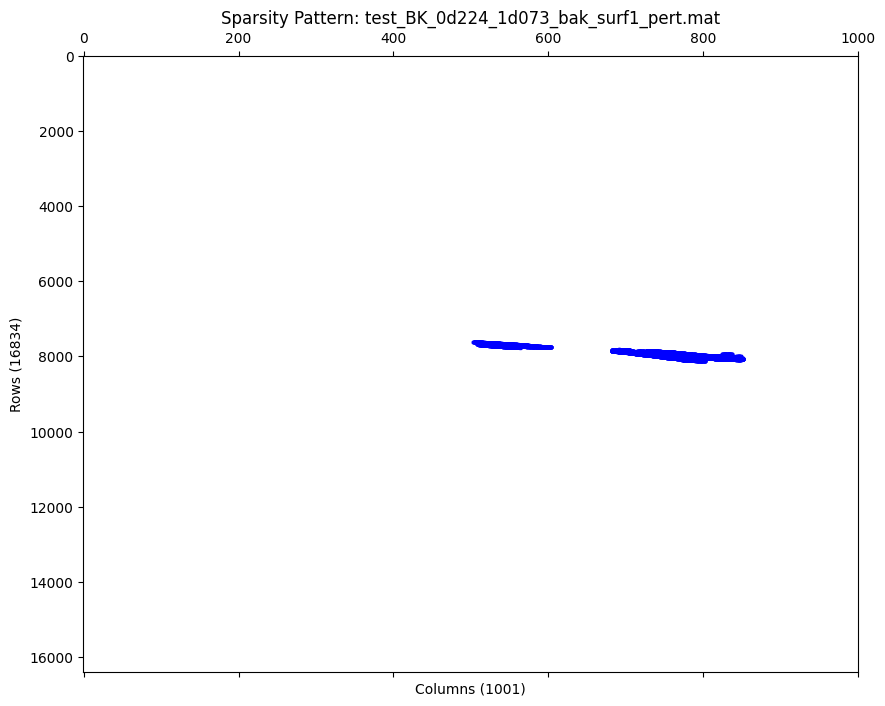

------------------------------------------------------------------------------------------
[test_BK_0d236_1d132_bak_surf1_pert.mat: eta] mean|left-right| = 3.369e-07, mean relative diff = 0.002116 (near 0 supports periodicity; large values suggest it's not periodic)
[test_BK_0d236_1d132_bak_surf1_pert.mat: ux] mean|left-right| = 1.98e-05, mean relative diff = 0.05804 (near 0 supports periodicity; large values suggest it's not periodic)

Processed test_BK_0d236_1d132_bak_surf1_pert.mat: added 33141 points (total: 50702)


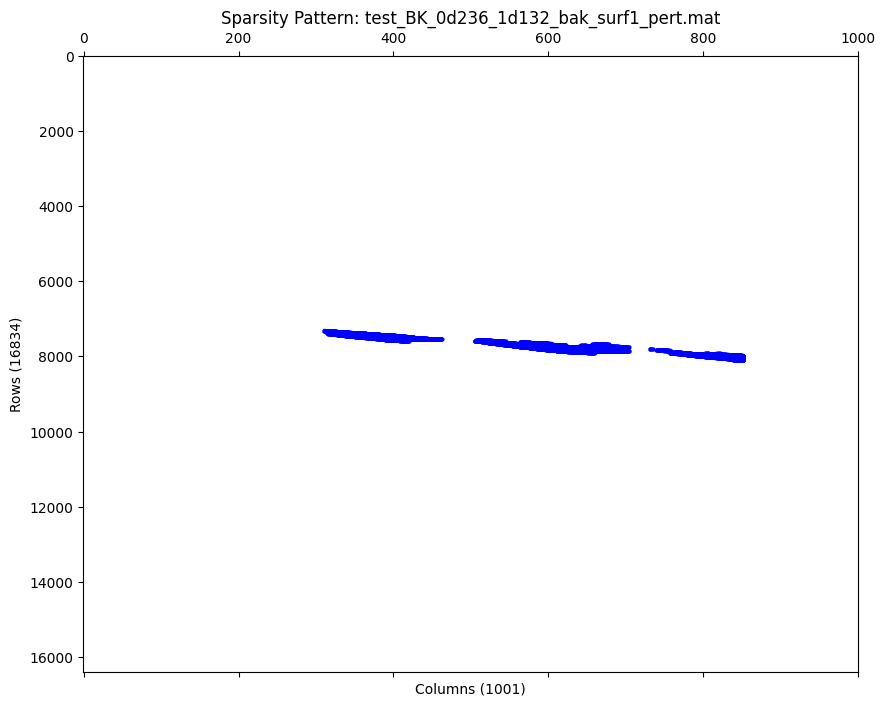

------------------------------------------------------------------------------------------
[test_BK_0d237_1d091_bak_surf1_pert.mat: eta] mean|left-right| = 1.187e-07, mean relative diff = 0.001806 (near 0 supports periodicity; large values suggest it's not periodic)
[test_BK_0d237_1d091_bak_surf1_pert.mat: ux] mean|left-right| = 2.8e-05, mean relative diff = 0.02063 (near 0 supports periodicity; large values suggest it's not periodic)

Processed test_BK_0d237_1d091_bak_surf1_pert.mat: added 34419 points (total: 85121)


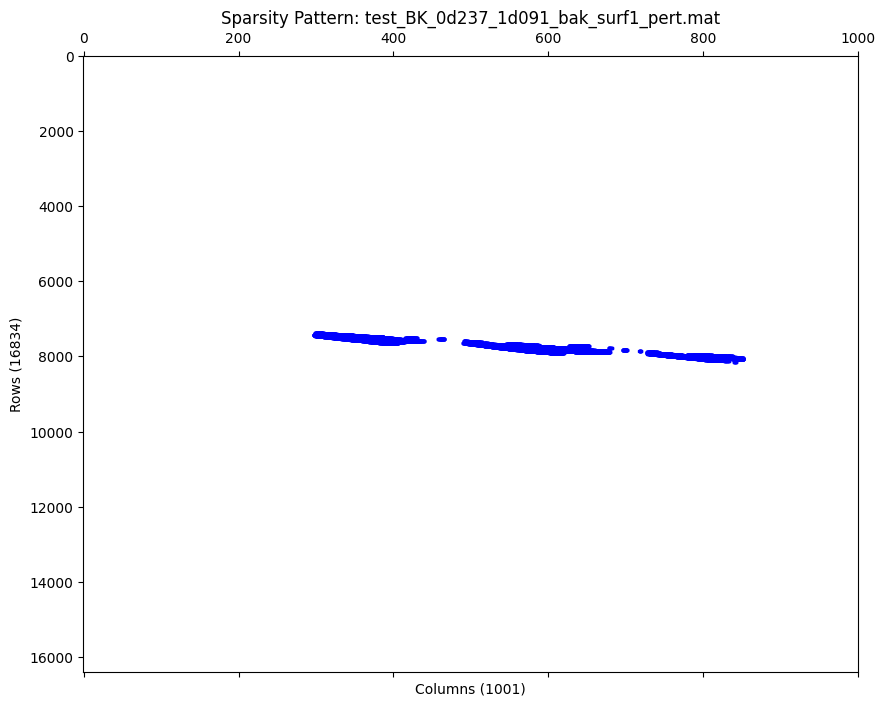

------------------------------------------------------------------------------------------
[test_BK_0d239_1d435_bak_surf1_pert.mat: eta] mean|left-right| = 6.464e-07, mean relative diff = 0.002302 (near 0 supports periodicity; large values suggest it's not periodic)
[test_BK_0d239_1d435_bak_surf1_pert.mat: ux] mean|left-right| = 2.267e-05, mean relative diff = 0.01401 (near 0 supports periodicity; large values suggest it's not periodic)

Processed test_BK_0d239_1d435_bak_surf1_pert.mat: added 36705 points (total: 121826)


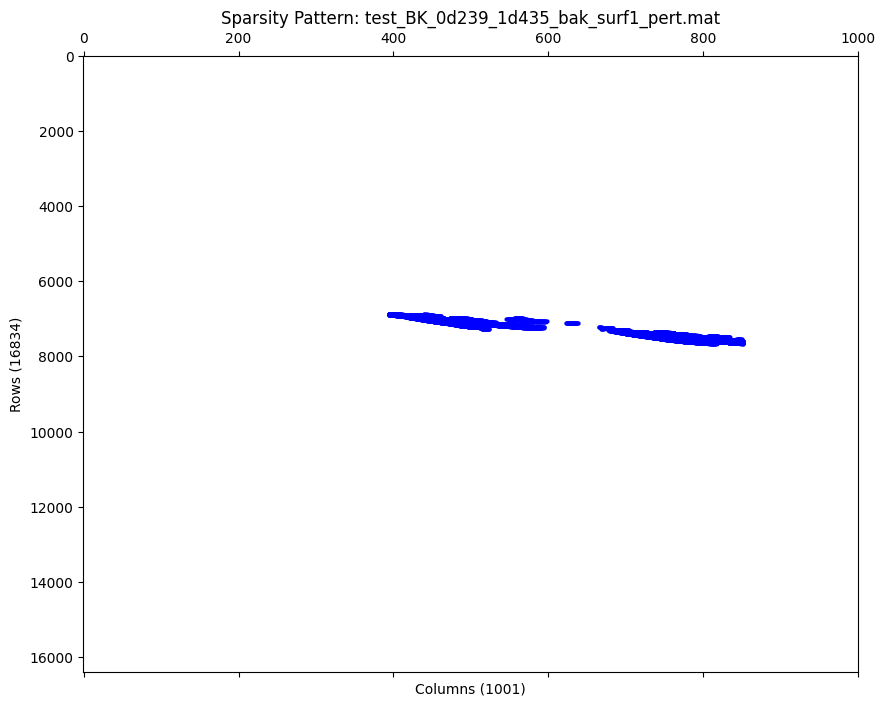

------------------------------------------------------------------------------------------
[test_BK_0d23_1d42_bak_surf1_pert.mat: eta] mean|left-right| = 4.379e-07, mean relative diff = 0.003278 (near 0 supports periodicity; large values suggest it's not periodic)
[test_BK_0d23_1d42_bak_surf1_pert.mat: ux] mean|left-right| = 9.404e-05, mean relative diff = 0.06893 (near 0 supports periodicity; large values suggest it's not periodic)

Processed test_BK_0d23_1d42_bak_surf1_pert.mat: added 21472 points (total: 143298)


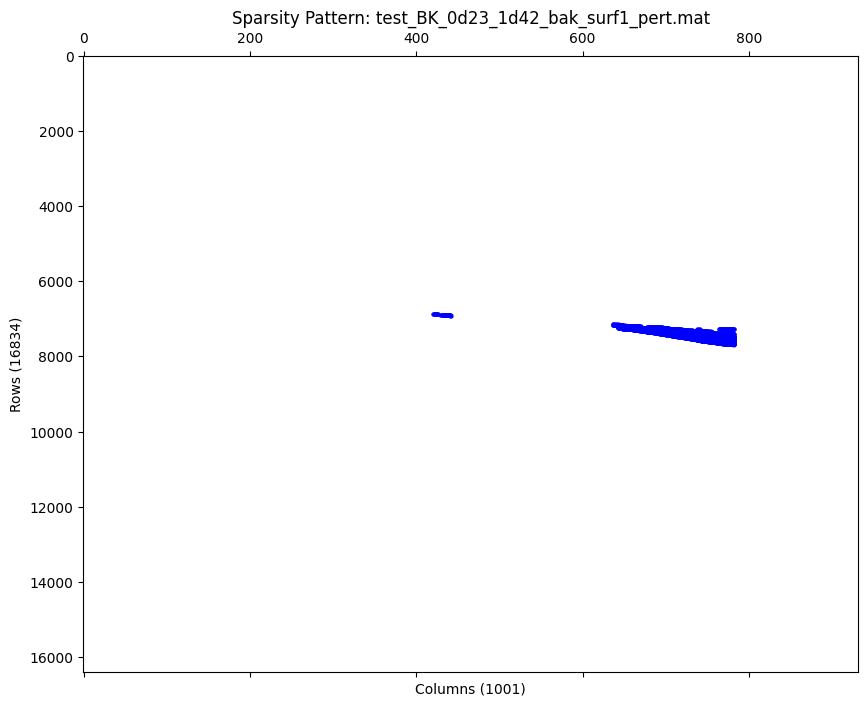

------------------------------------------------------------------------------------------
[test_BK_0d243_1d223_bak_surf1_pert.mat: eta] mean|left-right| = 6.22e-07, mean relative diff = 0.00362 (near 0 supports periodicity; large values suggest it's not periodic)
[test_BK_0d243_1d223_bak_surf1_pert.mat: ux] mean|left-right| = 0.0001165, mean relative diff = 0.0291 (near 0 supports periodicity; large values suggest it's not periodic)

Processed test_BK_0d243_1d223_bak_surf1_pert.mat: added 64394 points (total: 207692)


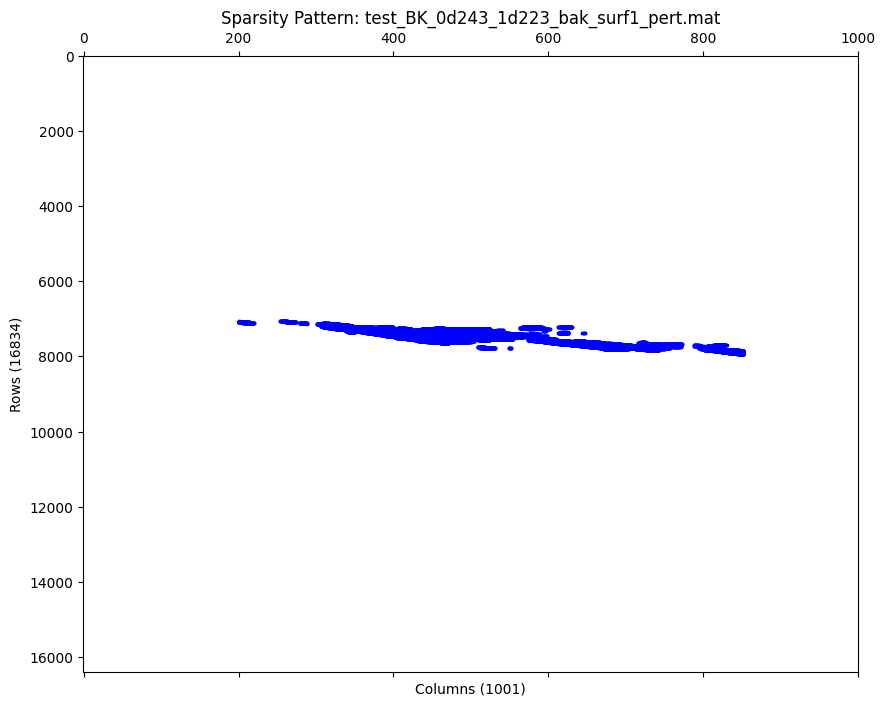

------------------------------------------------------------------------------------------
[test_BK_0d243_1d313_bak_surf1_pert.mat: eta] mean|left-right| = 1.768e-06, mean relative diff = 0.01958 (near 0 supports periodicity; large values suggest it's not periodic)
[test_BK_0d243_1d313_bak_surf1_pert.mat: ux] mean|left-right| = 2.308e-05, mean relative diff = 0.05024 (near 0 supports periodicity; large values suggest it's not periodic)

Processed test_BK_0d243_1d313_bak_surf1_pert.mat: added 48241 points (total: 255933)


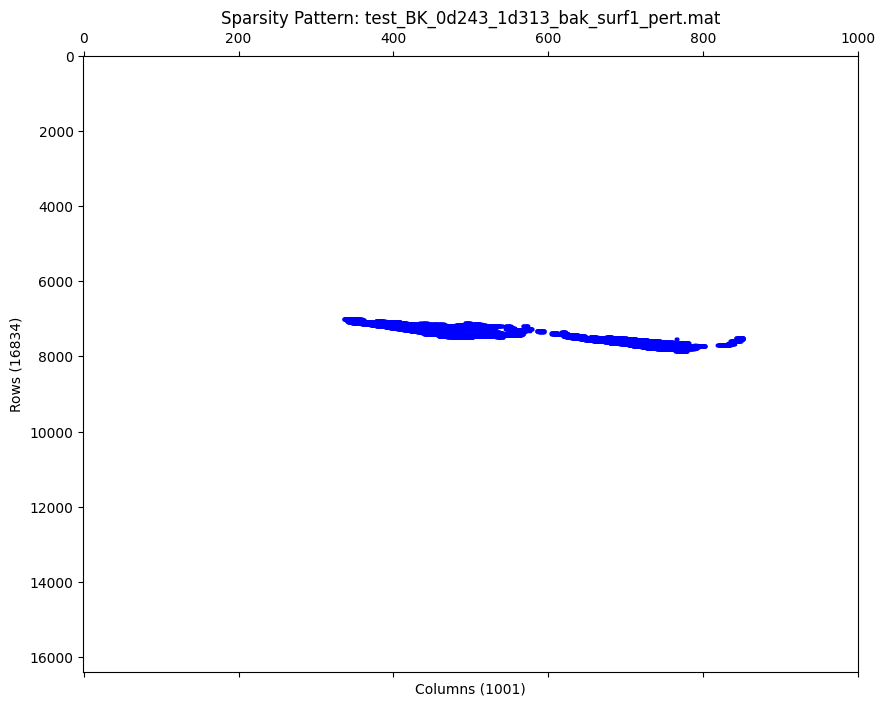

------------------------------------------------------------------------------------------
[test_BK_0d246_1d068_bak_surf1_pert.mat: eta] mean|left-right| = 1.747e-07, mean relative diff = 0.001839 (near 0 supports periodicity; large values suggest it's not periodic)
[test_BK_0d246_1d068_bak_surf1_pert.mat: ux] mean|left-right| = 1.733e-06, mean relative diff = 0.008758 (near 0 supports periodicity; large values suggest it's not periodic)

Processed test_BK_0d246_1d068_bak_surf1_pert.mat: added 29364 points (total: 285297)


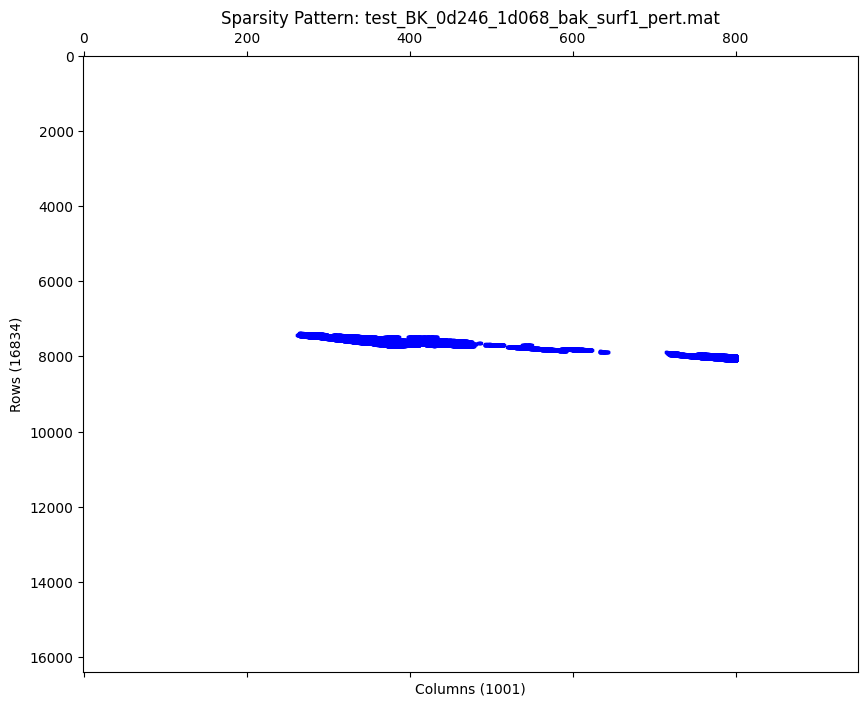

------------------------------------------------------------------------------------------
[test_BK_0d24_1d10_bak_surf1_pert.mat: eta] mean|left-right| = 2.912e-07, mean relative diff = 0.005131 (near 0 supports periodicity; large values suggest it's not periodic)
[test_BK_0d24_1d10_bak_surf1_pert.mat: ux] mean|left-right| = 5.206e-05, mean relative diff = 0.02578 (near 0 supports periodicity; large values suggest it's not periodic)

Processed test_BK_0d24_1d10_bak_surf1_pert.mat: added 27511 points (total: 312808)


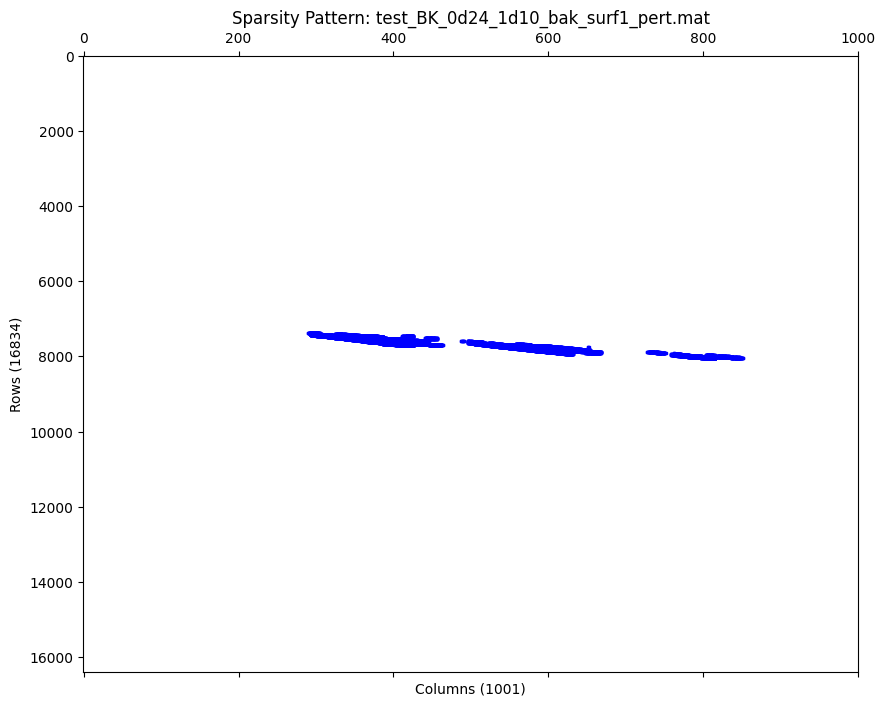

------------------------------------------------------------------------------------------
[test_BK_0d24_1d46_bak_surf1_pert.mat: eta] mean|left-right| = 1.463e-06, mean relative diff = 0.006647 (near 0 supports periodicity; large values suggest it's not periodic)
[test_BK_0d24_1d46_bak_surf1_pert.mat: ux] mean|left-right| = 0.0002767, mean relative diff = 0.03552 (near 0 supports periodicity; large values suggest it's not periodic)

Processed test_BK_0d24_1d46_bak_surf1_pert.mat: added 19559 points (total: 332367)


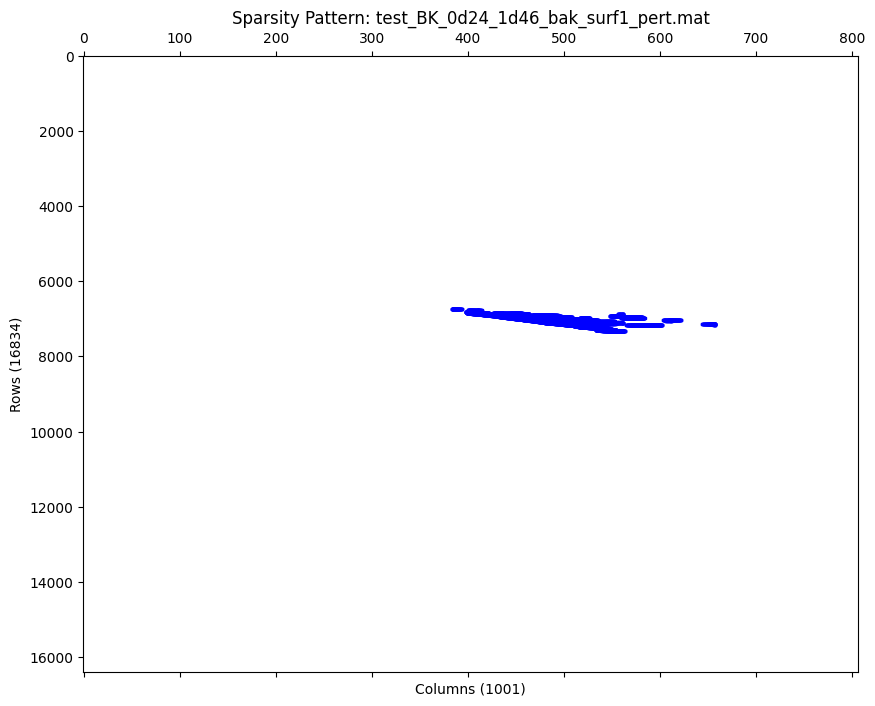

------------------------------------------------------------------------------------------
[test_MXBKBW_0d183_1d918_0d826_bak_surf1_pert.mat: eta] mean|left-right| = 3.832e-07, mean relative diff = 0.00614 (near 0 supports periodicity; large values suggest it's not periodic)
[test_MXBKBW_0d183_1d918_0d826_bak_surf1_pert.mat: ux] mean|left-right| = 9.084e-06, mean relative diff = 0.02406 (near 0 supports periodicity; large values suggest it's not periodic)

Processed test_MXBKBW_0d183_1d918_0d826_bak_surf1_pert.mat: added 0 points (total: 332367)


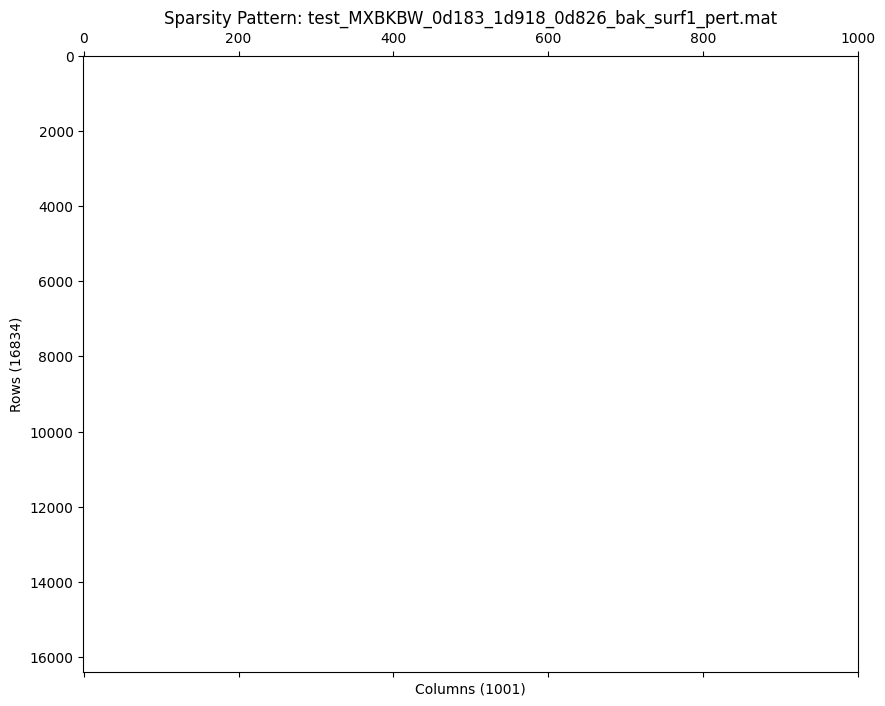

------------------------------------------------------------------------------------------
[test_MXBKBW_0d191_1d719_0d882_bak_surf1_pert.mat: eta] mean|left-right| = 2.693e-07, mean relative diff = 0.002463 (near 0 supports periodicity; large values suggest it's not periodic)
[test_MXBKBW_0d191_1d719_0d882_bak_surf1_pert.mat: ux] mean|left-right| = 4.723e-05, mean relative diff = 0.06501 (near 0 supports periodicity; large values suggest it's not periodic)

Processed test_MXBKBW_0d191_1d719_0d882_bak_surf1_pert.mat: added 0 points (total: 332367)


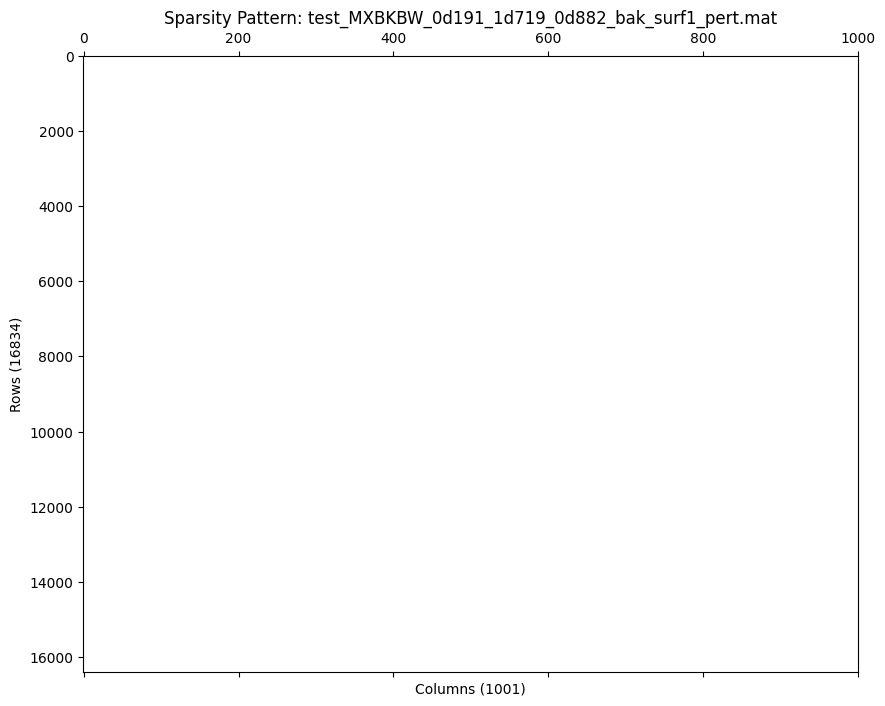

------------------------------------------------------------------------------------------
[test_MXBKBW_0d205_1d836_0d818_bak_surf1_pert.mat: eta] mean|left-right| = 4.126e-07, mean relative diff = 0.008929 (near 0 supports periodicity; large values suggest it's not periodic)
[test_MXBKBW_0d205_1d836_0d818_bak_surf1_pert.mat: ux] mean|left-right| = 2.956e-05, mean relative diff = 0.04334 (near 0 supports periodicity; large values suggest it's not periodic)

Processed test_MXBKBW_0d205_1d836_0d818_bak_surf1_pert.mat: added 3307 points (total: 335674)


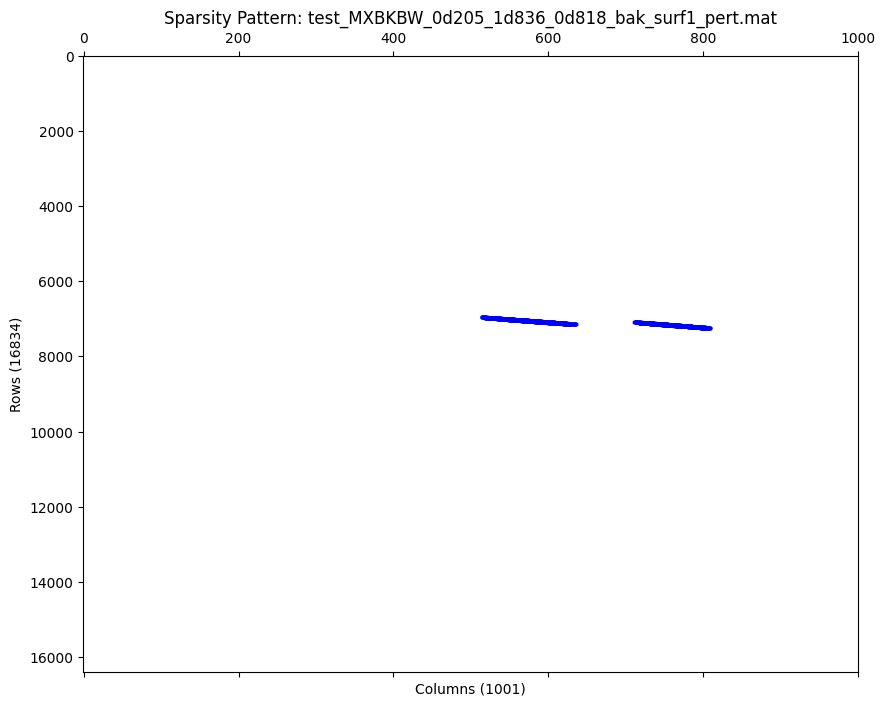

------------------------------------------------------------------------------------------
[test_MXBKBW_0d212_1d724_1d207_bak_surf1_pert.mat: eta] mean|left-right| = 2.71e-07, mean relative diff = 0.00616 (near 0 supports periodicity; large values suggest it's not periodic)
[test_MXBKBW_0d212_1d724_1d207_bak_surf1_pert.mat: ux] mean|left-right| = 3.038e-06, mean relative diff = 0.01249 (near 0 supports periodicity; large values suggest it's not periodic)

Processed test_MXBKBW_0d212_1d724_1d207_bak_surf1_pert.mat: added 0 points (total: 335674)


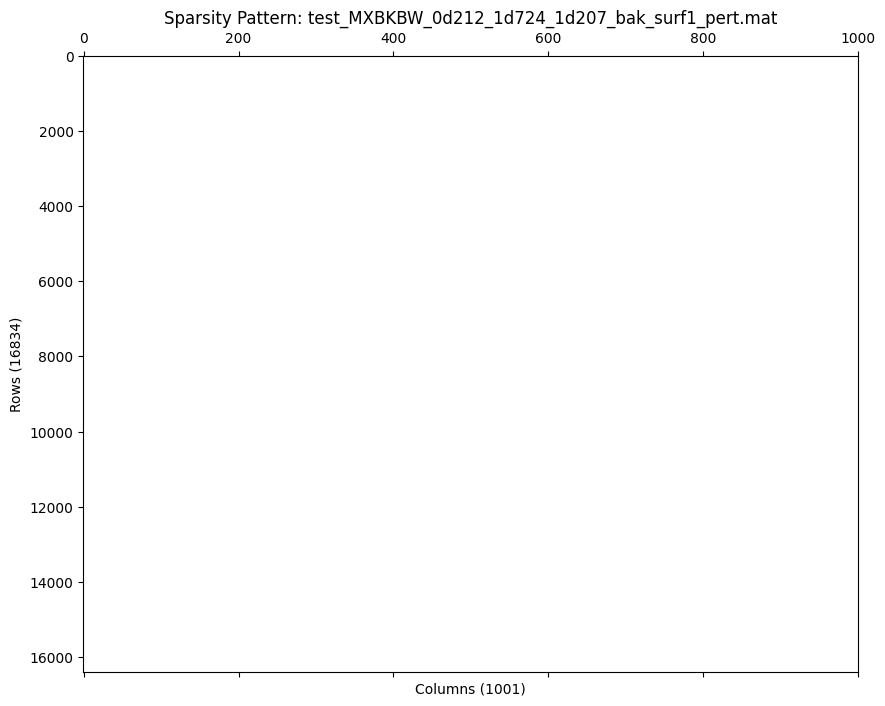

------------------------------------------------------------------------------------------
[test_MXBKBW_0d222_1d337_1d248_bak_surf1_pert.mat: eta] mean|left-right| = 2.71e-07, mean relative diff = 0.00616 (near 0 supports periodicity; large values suggest it's not periodic)
[test_MXBKBW_0d222_1d337_1d248_bak_surf1_pert.mat: ux] mean|left-right| = 3.038e-06, mean relative diff = 0.01249 (near 0 supports periodicity; large values suggest it's not periodic)

Processed test_MXBKBW_0d222_1d337_1d248_bak_surf1_pert.mat: added 0 points (total: 335674)


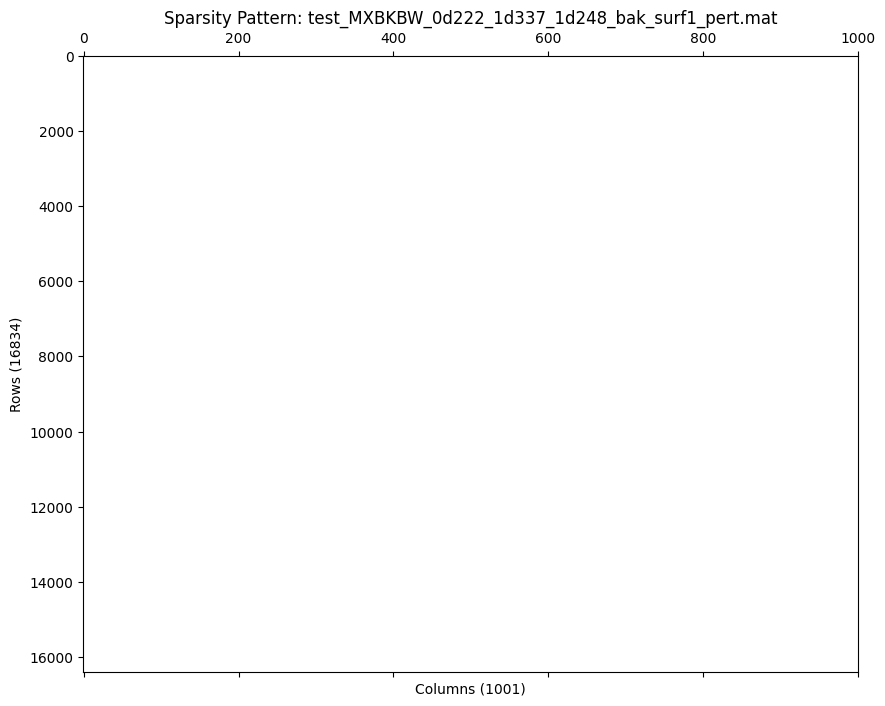

------------------------------------------------------------------------------------------
[test_MXBKBW_0d234_1d772_0d823_bak_surf1_pert.mat: eta] mean|left-right| = 4.482e-07, mean relative diff = 0.00578 (near 0 supports periodicity; large values suggest it's not periodic)
[test_MXBKBW_0d234_1d772_0d823_bak_surf1_pert.mat: ux] mean|left-right| = 6.415e-05, mean relative diff = 0.04232 (near 0 supports periodicity; large values suggest it's not periodic)

Processed test_MXBKBW_0d234_1d772_0d823_bak_surf1_pert.mat: added 26563 points (total: 362237)


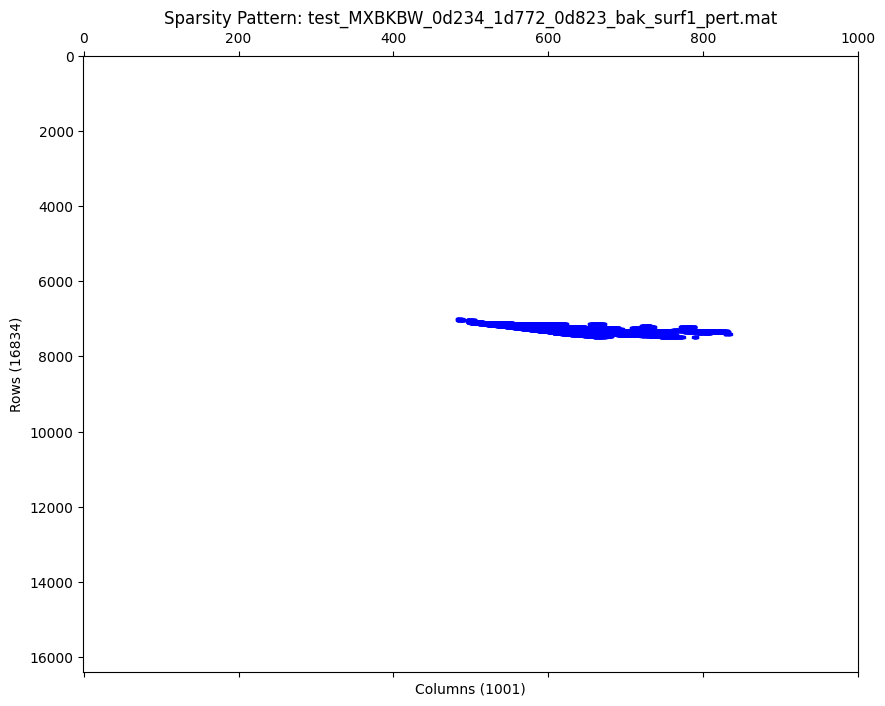

------------------------------------------------------------------------------------------
[test_MXBK_0d174_1d050_bak_surf1_pert.mat: eta] mean|left-right| = 9.081e-08, mean relative diff = 0.001314 (near 0 supports periodicity; large values suggest it's not periodic)
[test_MXBK_0d174_1d050_bak_surf1_pert.mat: ux] mean|left-right| = 2.289e-05, mean relative diff = 0.03094 (near 0 supports periodicity; large values suggest it's not periodic)

Processed test_MXBK_0d174_1d050_bak_surf1_pert.mat: added 0 points (total: 362237)


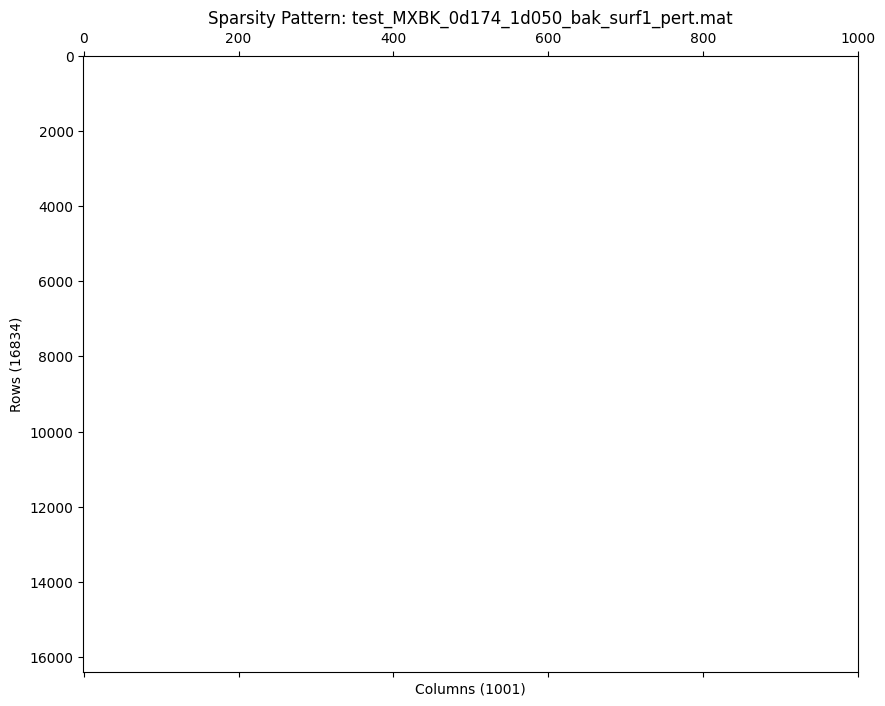

------------------------------------------------------------------------------------------
[test_MXBK_0d180_1d189_bak_surf1_pert.mat: eta] mean|left-right| = 1.294e-07, mean relative diff = 0.002215 (near 0 supports periodicity; large values suggest it's not periodic)
[test_MXBK_0d180_1d189_bak_surf1_pert.mat: ux] mean|left-right| = 3.153e-05, mean relative diff = 0.03444 (near 0 supports periodicity; large values suggest it's not periodic)

Processed test_MXBK_0d180_1d189_bak_surf1_pert.mat: added 0 points (total: 362237)


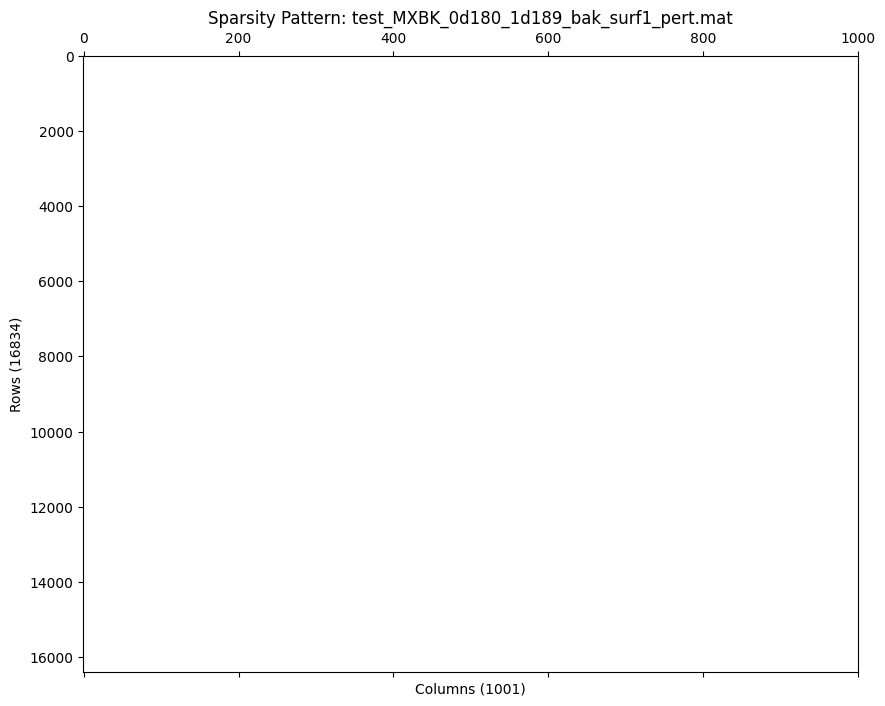

------------------------------------------------------------------------------------------
[test_MXBK_0d189_1d252_bak_surf1_pert.mat: eta] mean|left-right| = 1.814e-07, mean relative diff = 0.002509 (near 0 supports periodicity; large values suggest it's not periodic)
[test_MXBK_0d189_1d252_bak_surf1_pert.mat: ux] mean|left-right| = 4.349e-05, mean relative diff = 0.04814 (near 0 supports periodicity; large values suggest it's not periodic)

Processed test_MXBK_0d189_1d252_bak_surf1_pert.mat: added 0 points (total: 362237)


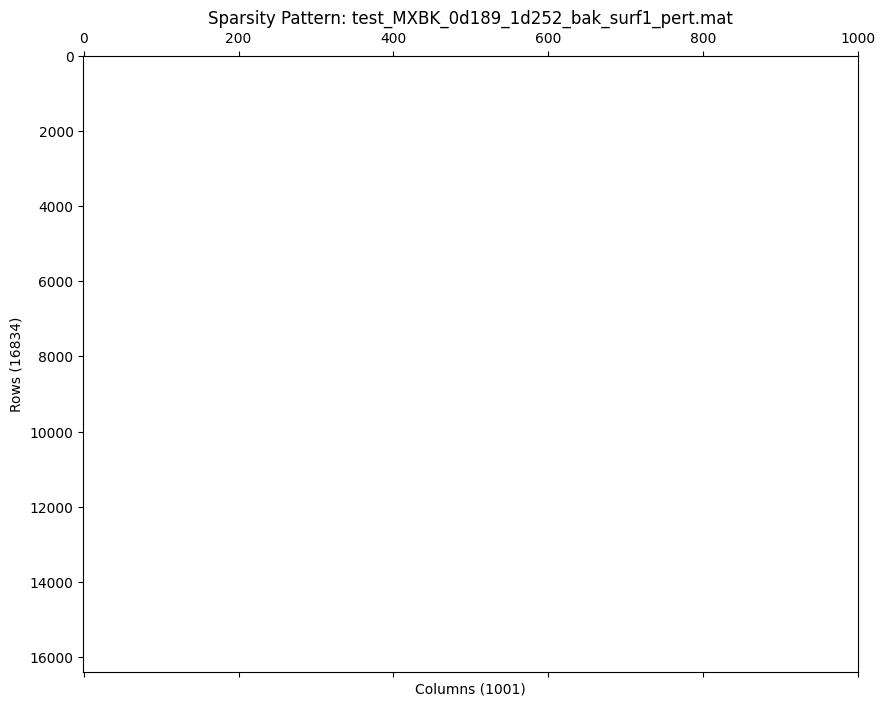

------------------------------------------------------------------------------------------
[test_MXBK_0d203_0d845_bak_surf1_pert.mat: eta] mean|left-right| = nan, mean relative diff = nan (near 0 supports periodicity; large values suggest it's not periodic)
[test_MXBK_0d203_0d845_bak_surf1_pert.mat: ux] mean|left-right| = nan, mean relative diff = nan (near 0 supports periodicity; large values suggest it's not periodic)

Processed test_MXBK_0d203_0d845_bak_surf1_pert.mat: added 0 points (total: 362237)


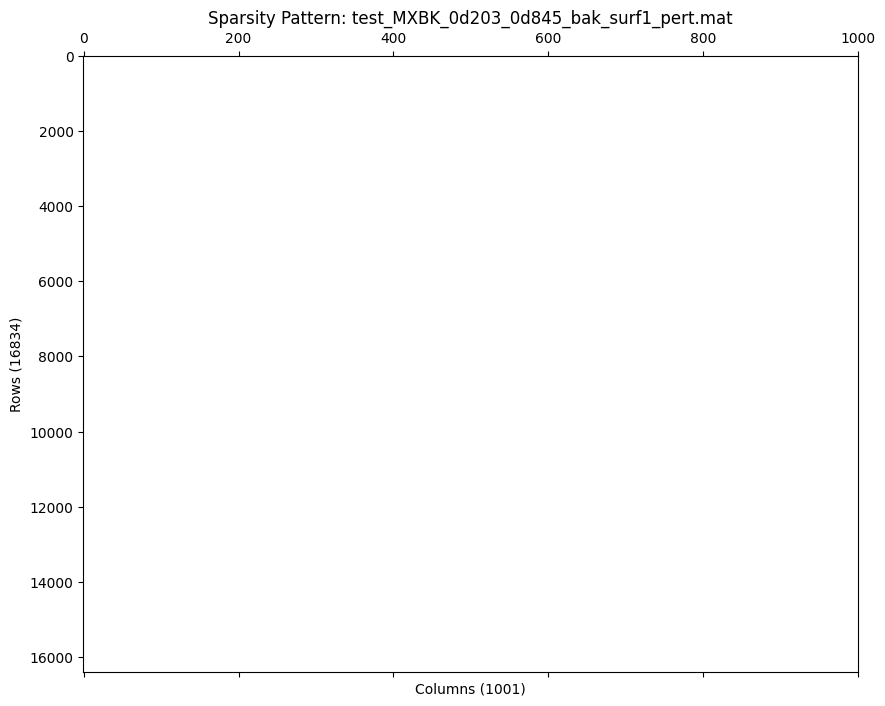

------------------------------------------------------------------------------------------
Saved dataset with 362237 rows to final_dataset\db_database_full_discover_160826.mat


In [ ]:
BOUNDARY_MODE = "periodic"
RUN_PERIODICITY_CHECK = True
DATA_DIR = r"data"
OUTPUT_DIR = r"final_dataset"

name_list = os.listdir(r"data")

N_PREALLOC = 1_000_000
N_FEATURES = 15

u_in = np.zeros((N_PREALLOC, N_FEATURES))
tar_eta_full = np.zeros(N_PREALLOC)
tar_eta_residual = np.zeros(N_PREALLOC)
process_num = 0 


for name in name_list:
    fpath = os.path.join(DATA_DIR, f"{name}")
    if not os.path.exists(fpath):
        print(name)
        continue

    data = read_mat(fpath)
    sfr3 = data["sfr3"]
    time_vec = np.asarray(data["time_vec"]).ravel()
    x1 = np.asarray(data["x1"]).ravel()
    time_len_min = int(data["time_len_min"])

    
    for key in list(sfr3.keys()):
        sfr3[key] = np.asarray(sfr3[key])[:, :time_len_min]

    t = time_vec
    x = x1
    dx = x[2] - x[1]

    if RUN_PERIODICITY_CHECK:
        check_periodicity_assumption(sfr3["eta"], x, label=f"{name}: eta")
        check_periodicity_assumption(sfr3["ux"], x, label=f"{name}: ux")
        print("")

    eta_smooth = spline_smooth_5(sfr3["eta"], t, x)
    ux_smooth = spline_smooth_5(sfr3["ux"], t, x)
    uy_smooth = spline_smooth_5(sfr3["uy"], t, x)

    deta_dt = -grad1(sfr3["eta"], time_vec[1] - time_vec[0])
    deta_dt_smooth = spline_smooth_5(deta_dt, t, x)

    deta_dx = -grad1(sfr3["eta"].T, x[1] - x[0], boundary=BOUNDARY_MODE).T
    deta_dx_smooth = spline_smooth_5(deta_dx, t, x)

    deta_dx2 = -grad1(deta_dx.T, x[1] - x[0], boundary=BOUNDARY_MODE).T
    deta_dx2_smooth = spline_smooth_5(deta_dx2, t, x)

    ux = np.squeeze(sfr3["ux"])
    dudx = -grad1(ux.T, x[1] - x[0], boundary=BOUNDARY_MODE).T
    dudx_smooth = spline_smooth_5(dudx, t, x)

    uy = np.squeeze(sfr3["uy"])
    duydx = -grad1(uy.T, x[1] - x[0], boundary=BOUNDARY_MODE).T
    duydx_smooth = spline_smooth_5(duydx, t, x)

    duydy_smooth = spline_smooth_5(sfr3["dwd_y"], t, x)

    ut_x = np.squeeze(sfr3["dudt_T_x"])
    du_dt = -grad1(ux, time_vec[1] - time_vec[0])
    du_dt_smooth = spline_smooth_5(du_dt, t, x)

    sfr3["eta"] = spline_smooth_5(sfr3["eta"], t, x)
    sfr3["ux"] = spline_smooth_5(sfr3["ux"], t, x)
    sfr3["uy"] = spline_smooth_5(sfr3["uy"], t, x)
    sfr3["dud_x"] = spline_smooth_5(sfr3["dud_x"], t, x)
    sfr3["dud_y"] = spline_smooth_5(sfr3["dud_y"], t, x)
    sfr3["dwd_x"] = spline_smooth_5(sfr3["dwd_x"], t, x)
    sfr3["dwd_y"] = spline_smooth_5(sfr3["dwd_y"], t, x)
    sfr3["dudt_T_x"] = spline_smooth_5(sfr3["dudt_T_x"], t, x)
    sfr3["dudt_T_y"] = spline_smooth_5(sfr3["dudt_T_y"], t, x)
    sfr3["p"] = spline_smooth_5(sfr3["p"], t, x)

    sfr = sfr3

    # "..._1d42" -> 1.42
    n_s = name.split("_")
    T_s = n_s[3].split("d")
    Tp = float(T_s[0]) + float("0." + T_s[1])
    f = 1 / Tp
    k = (2 * np.pi * f) ** 2 / 9.81
    omega = 2 * np.pi * f

    RHS = (
        -9.81 * deta_dx_smooth
        - dudx_smooth * sfr["ux"]
        - (duydx_smooth * sfr["uy"])
        - sfr["uy"] * duydx_smooth * deta_dx_smooth ** 2
        - sfr["uy"] ** 2 * deta_dx_smooth * deta_dx2_smooth
    )

    result = du_dt_smooth - RHS

    MSK = np.abs(result) >= 0.04 * np.max(np.abs(result))
    MSK[:, :200] = False
    MSK[:, -1:-150:-1] = False

    eta_x_temp = deta_dx_smooth[MSK]
    num_data_points = eta_x_temp.shape[0]

    eta_H_time = hilbert(sfr["eta"], axis=1)
    eta_H_space = hilbert(sfr["eta"], axis=0)

    residual_full = du_dt_smooth
    residual_res = du_dt_smooth - RHS

    end_idx = process_num + num_data_points

    u_in[process_num:end_idx, 0] = deta_dx_smooth[MSK]
    u_in[process_num:end_idx, 1] = sfr["uy"][MSK]
    u_in[process_num:end_idx, 2] = sfr["ux"][MSK]
    u_in[process_num:end_idx, 3] = dudx_smooth[MSK]
    u_in[process_num:end_idx, 4] = sfr["dud_y"][MSK]
    u_in[process_num:end_idx, 5] = duydx_smooth[MSK]
    u_in[process_num:end_idx, 6] = sfr["dwd_y"][MSK]
    u_in[process_num:end_idx, 7] = deta_dx2[MSK]
    u_in[process_num:end_idx, 8] = np.imag(eta_H_time[MSK])
    u_in[process_num:end_idx, 9] = np.imag(eta_H_space[MSK])
    u_in[process_num:end_idx, 10] = np.abs(eta_H_time[MSK])
    u_in[process_num:end_idx, 11] = np.abs(eta_H_space[MSK])
    u_in[process_num:end_idx, 12] = eta_smooth[MSK]
    u_in[process_num:end_idx, 13] = eta_smooth[MSK] * 0 + k
    u_in[process_num:end_idx, 14] = eta_smooth[MSK] * 0 + omega

    tar_eta_full[process_num:end_idx] = residual_full[MSK]
    tar_eta_residual[process_num:end_idx] = residual_res[MSK]

    process_num = end_idx
    print(f"Processed {name}: added {num_data_points} points (total: {process_num})")
    
    plt.figure(figsize=(10, 8))
    
    plt.spy(np.copy(MSK), aspect='auto', markersize=2, color='blue')
    plt.title(f"Sparsity Pattern: {name}")
    plt.xlabel("Columns (1001)")
    plt.ylabel("Rows (16834)")
    plt.show()
    print("-"*90)

u_in = u_in[:process_num, :]
tar_eta_residual = tar_eta_residual[:process_num]
tar_eta_full = tar_eta_full[:process_num]

t_save = datetime.now().strftime("%d%m%y")
out_path = os.path.join(OUTPUT_DIR, f"db_database_full_discover_{t_save}.mat")

savemat(
    out_path,
    {
        "u_in": u_in,
        "tar_eta_full": tar_eta_full,
        "tar_eta_residual": tar_eta_residual,
    },
)
print(f"Saved dataset with {process_num} rows to {out_path}")

### Training

In [2]:
file_path = r"final_dataset\db_database_full_discover_160826.mat"
f = read_mat(file_path)

X_full = f['u_in']
y_res = f['tar_eta_residual']
y_full = f['tar_eta_full']

k, omega = X_full[:, 13], X_full[:, 14]

X_tilde = np.zeros_like(X_full)

X_tilde[:, 0] = X_full[:, 0]  # deta_dx (already dimensionless [-])
X_tilde[:, 1] = X_full[:, 1] * (k / omega)  # uy / c_p
X_tilde[:, 2] = X_full[:, 2] * (k / omega)  # ux / c_p
X_tilde[:, 3] = X_full[:, 3] / omega  # dudx / omega
# X_tilde[:, 4] = X_full[:, 4] / omega  # dudy / omega
X_tilde[:, 5] = X_full[:, 5] / omega  # duydx / omega
# X_tilde[:, 6] = X_full[:, 6] / omega  # duydy / omega
"""deta_dx2 not taken because of absurd ranges"""
X_tilde[:, 7] = X_full[:, 7] / k  # deta_dx2 / k 
X_tilde[:, 8] = X_full[:, 8] * k  # k * hilbert_t_img
X_tilde[:, 9] = X_full[:, 9] * k  # k * hilbert_x_img
X_tilde[:, 10] = X_full[:, 10] * k  # k * hilbert_t_abs
X_tilde[:, 11] = X_full[:, 11] * k  # k * hilbert_x_abs
X_tilde[:, 12] = X_full[:, 12] * k  # k * eta (wave steepness)

y_res_tilde = y_res * (k / (omega**2))
y_full_tilde = y_full * (k / (omega**2))

In [3]:
meow = X_tilde[:,7]
np.min(meow)
np.sum(np.abs(meow) > 50) / len(meow)

np.float64(0.061468044401869495)

In [4]:
import pandas as pd
df = pd.DataFrame(X_tilde)
df

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
0,0.319785,-0.272369,0.255001,0.458362,0.0,0.195669,0.0,0.609958,0.248852,-0.249126,0.303240,0.303465,0.173284,0.0,0.0
1,0.299394,-0.253512,0.291399,0.436182,0.0,0.247181,0.0,0.443350,0.230077,-0.230331,0.304550,0.304742,0.199537,0.0,0.0
2,0.313781,-0.266579,0.267869,0.451365,0.0,0.213774,0.0,0.571182,0.243023,-0.243301,0.303766,0.303988,0.182245,0.0,0.0
3,0.325399,-0.277875,0.243594,0.462326,0.0,0.180365,0.0,0.607563,0.254506,-0.254781,0.302889,0.303121,0.164221,0.0,0.0
4,0.291005,-0.246255,0.303599,0.425212,0.0,0.265322,0.0,0.181666,0.223054,-0.223326,0.304918,0.305117,0.207899,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
362232,0.175647,-0.142011,0.194720,0.079509,0.0,0.050034,0.0,-14.757812,0.120307,-0.115128,0.127009,0.122114,-0.040713,0.0,0.0
362233,0.176551,-0.142924,0.184303,0.068408,0.0,0.044515,0.0,-10.131896,0.120270,-0.114631,0.128766,0.123515,-0.045998,0.0,0.0
362234,0.176955,-0.143498,0.173965,0.056814,0.0,0.039576,0.0,-4.856701,0.119167,-0.113887,0.129734,0.124901,-0.051284,0.0,0.0
362235,0.173268,-0.139320,0.207393,0.159017,0.0,0.104785,0.0,-11.694504,0.119887,-0.114614,0.124169,0.119086,-0.032327,0.0,0.0


In [5]:
# Keep only the columns actually populated, in order
keep_cols = [0, 1, 2, 3, 5, 8, 9, 10, 11, 12]
X_pysr = X_tilde[:, keep_cols]

feature_names = [
    "deta_dx", "uy_tilde", "ux_tilde", "dudx_tilde", "duydx_tilde",
    "hilbert_t_img_tilde", "hilbert_x_img_tilde",
    "hilbert_t_abs_tilde", "hilbert_x_abs_tilde", "eta_tilde",
]

'''reference = [
# x0: Surface slope (deta/dx)
# x1: Vertical velocity (v)
# x2: Horizontal velocity (u)
# x3: Velocity gradient (du/dx)
# x4: Vertical derivative of horizontal velocity
# x5: Vertical velocity gradient (dv/dx)
# x6: Vertical velocity gradient (dv/dy)
# x7: Surface curvature (d2eta/dx2)
# x8: Imaginary Hilbert (time)
# x9: Imaginary Hilbert (space)
# x10: Envelope amplitude (time)
# x11: Envelope amplitude (space)
# x12: Surface elevation
]
'''

np.random.seed(42)
total_samples = X_pysr.shape[0]
train_size = 10000

indices = np.random.permutation(total_samples)
train_idx, test_idx = indices[:train_size], indices[train_size:]

X_train, y_train = X_pysr[train_idx], y_res_tilde[train_idx]
X_test, y_test = X_pysr[test_idx], y_res_tilde[test_idx]

print(f"Dataset split: {X_train.shape[0]} training samples, {X_test.shape[0]} test samples.")

Dataset split: 10000 training samples, 352237 test samples.


In [6]:
y_test

array([ 0.11955931, -0.04563436, -0.13161966, ...,  0.05838589,
        0.0289783 , -0.05878664], shape=(352237,))

In [ ]:
import numpy as np
from pysr import PySRRegressor

model = PySRRegressor(
    niterations=100,
    populations=30,
    population_size=40,
    binary_operators=["+", "-", "*", "/"],
    unary_operators=["square", "cube", "abs", "sin", "cos", "tanh", "exp"],
    extra_sympy_mappings={},
    
    # Complexity penalties
    parsimony=0.005,
    maxsize=20,
    
    # Parallel processing settings
    parallelism="multithreading",
    random_state=42,
    # elementwise_loss="L1DistLoss()"
)

model.fit(X_train, y_train, variable_names=feature_names)


best_eq = model.get_best()
print("\n--- Best Discovered Symbolic Equation ---")
print(f"Equation: {best_eq['equation']}")
print(f"Training MSE: {best_eq['loss']:.6f}")

# Predict on test set
y_pred_test = model.predict(X_test)
test_mse = np.mean((y_pred_test - y_test) ** 2)
print(f"Holdout Test MSE: {test_mse:.6f}")

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


c:\Users\Kshitij Jha\AppData\Local\Programs\Python\Python311\Lib\site-packages\pysr\sr.py:2811: UserWarning: Note: it looks like you are running in Jupyter. The progress bar will be turned off.
  warnings.warn(
Compiling Julia backend...
c:\Users\Kshitij Jha\AppData\Local\Programs\Python\Python311\Lib\site-packages\pysr\sr.py:1873: UserWarning: Note: Setting `random_state` without also setting `deterministic=True` and `parallelism='serial'` will result in non-deterministic searches.
  warnings.warn(
[ Info: Started!



Expressions evaluated per second: 1.820e+04
Progress: 79 / 3000 total iterations (2.633%)
════════════════════════════════════════════════════════════════════════════════════════════════════
───────────────────────────────────────────────────────────────────────────────────────────────────
Complexity  Loss       Score      Equation
1           2.398e-02  0.000e+00  y = 0.023356
2           2.379e-02  7.863e-03  y = cube(hilbert_x_img_tilde)
3           1.887e-02  2.318e-01  y = hilbert_t_img_tilde * -0.47811
5           1.754e-02  3.642e-02  y = (-0.69342 + hilbert_x_abs_tilde) * hilbert_t_img_tilde
6           1.746e-02  4.636e-03  y = (hilbert_x_abs_tilde + -0.74257) * tanh(hilbert_t_img_...
                                      tilde)
7           1.625e-02  7.215e-02  y = (hilbert_x_img_tilde * 2.0472) * cos(exp(hilbert_x_abs...
                                      _tilde))
8           1.595e-02  1.850e-02  y = tanh(hilbert_x_img_tilde * 2.3076) * cos(exp(hilbert_x...
            

Equation: `(0.15844892 - (hilbert_t_img_tilde + square(tanh(ux_tilde)))) * square(((uy_tilde + uy_tilde) + dudx_tilde) - 0.60992765)`
$$\left[ 0.15844892 - \left( \tilde{H}_t + \tanh^2(\tilde{u}_x) \right) \right] \cdot \left[ \left( 2\tilde{u}_y + \frac{\partial \tilde{u}}{\partial x} \right) - 0.60992765 \right]^2$$


In [10]:
from pysr import PySRRegressor

model = PySRRegressor.from_file(run_directory="outputs/20260822_111126_kMNrC7")

Attempting to load model from outputs\20260822_111126_kMNrC7\checkpoint.pkl...


In [24]:
model.equations_

,complexity,loss,equation,score,sympy_format,lambda_format
0,1,0.023979,0.023355419,0.000000,0.0233554190000000,PySRFunction(X=>0.0233554190000000)
1,2,0.023792,cube(hilbert_x_img_tilde),0.007863,hilbert_x_img_tilde**3,PySRFunction(X=>hilbert_x_img_tilde**3)
2,3,0.018870,hilbert_t_img_tilde * -0.47814202,0.231774,hilbert_t_img_tilde*(-0.47814202),PySRFunction(X=>hilbert_t_img_tilde*(-0.478142...
3,4,0.018803,tanh(hilbert_t_img_tilde) * -0.48953554,0.003559,tanh(hilbert_t_img_tilde)*(-0.48953554),PySRFunction(X=>tanh(hilbert_t_img_tilde)*(-0....
4,5,0.014550,hilbert_t_img_tilde * (-0.13024999 / hilbert_x...,0.256382,hilbert_t_img_tilde*(-0.13024999)/hilbert_x_ab...,PySRFunction(X=>hilbert_t_img_tilde*(-0.130249...
5,6,0.014497,(tanh(hilbert_t_img_tilde) * -0.13205393) / hi...,0.003700,tanh(hilbert_t_img_tilde)*(-0.13205393)/hilber...,PySRFunction(X=>tanh(hilbert_t_img_tilde)*(-0....
6,7,0.013306,hilbert_t_img_tilde * ((-0.17233042 / hilbert_...,0.085734,hilbert_t_img_tilde*(hilbert_x_abs_tilde - 0.1...,PySRFunction(X=>hilbert_t_img_tilde*(hilbert_x...
7,8,0.012553,(0.2713893 - square(ux_tilde)) * (0.24647853 -...,0.058248,(0.24647853 - dudx_tilde)*(0.2713893 - ux_tild...,PySRFunction(X=>(0.24647853 - dudx_tilde)*(0.2...
8,9,0.012386,(0.278028 - square(ux_tilde)) * (0.24088736 - ...,0.013403,(0.24088736 - tanh(dudx_tilde))*(0.278028 - ux...,PySRFunction(X=>(0.24088736 - tanh(dudx_tilde)...
9,10,0.011303,(0.19721799 - square(hilbert_t_img_tilde + ux_...,0.091491,(0.19721799 - (hilbert_t_img_tilde + ux_tilde)...,PySRFunction(X=>(0.19721799 - (hilbert_t_img_t...


In [41]:
y_pred_test = model.predict(X_test, index=18)

In [43]:
specific_equation = model.sympy(index=18)
print(specific_equation)

(0.20291464 - (hilbert_t_img_tilde + tanh(ux_tilde)**2))*(deta_dx - hilbert_x_abs_tilde - (dudx_tilde + uy_tilde) - 1*(-0.85715157))**2 - 1*0.049913824


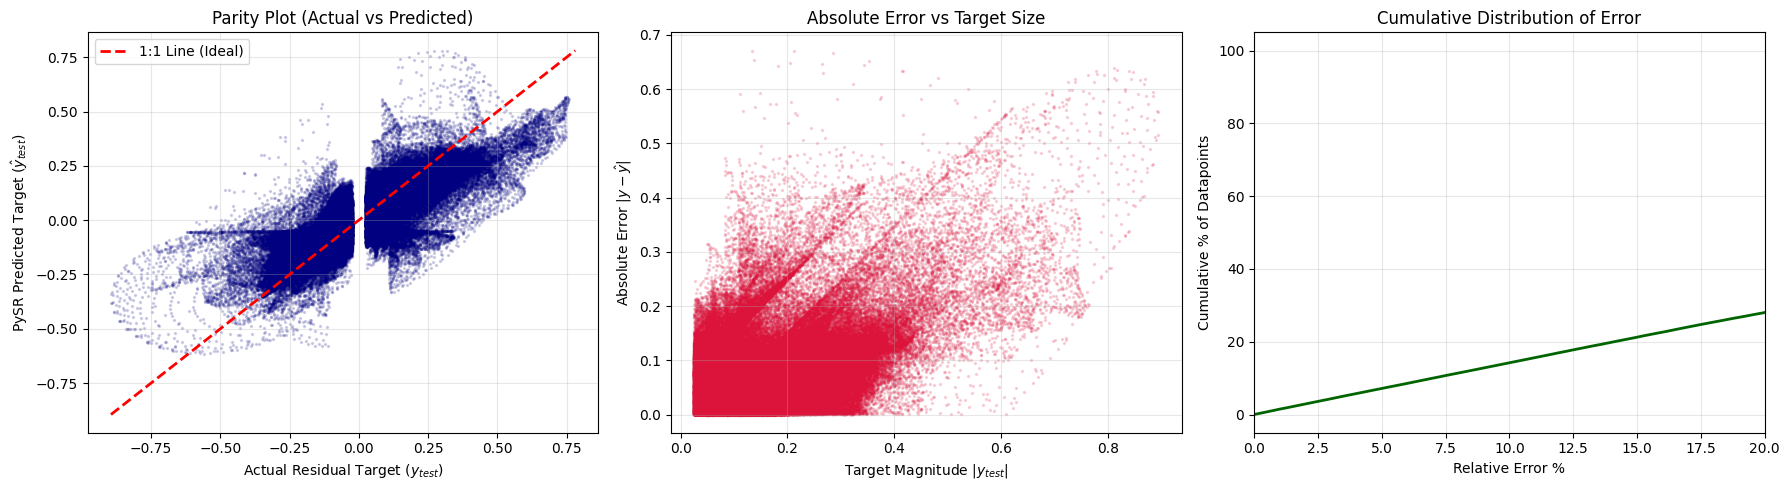

--- Corrected Error Analysis (excluding near-zero points |y| < 0.01) ---
• Filtered Max Error  : 890.03%
• Filtered Mean Error : 61.22%
• 90th Percentile Err : 146.56%


In [44]:
import numpy as np
import matplotlib.pyplot as plt

y_pred_test = model.predict(X_test, index=18)
abs_err = np.abs(y_pred_test - y_test)
eps = 1e-5
rel_err_safe = (abs_err / (np.abs(y_test) + eps)) * 100


fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Parity Plot (Actual vs Predicted)
axes[0].scatter(y_test, y_pred_test, alpha=0.15, s=2, color='navy')
min_val = min(np.min(y_test), np.min(y_pred_test))
max_val = max(np.max(y_test), np.max(y_pred_test))
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='1:1 Line (Ideal)')
axes[0].set_xlabel('Actual Residual Target ($y_{test}$)')
axes[0].set_ylabel('PySR Predicted Target ($\hat{y}_{test}$)')
axes[0].set_title('Parity Plot (Actual vs Predicted)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Absolute Error vs Target Magnitude
axes[1].scatter(np.abs(y_test), abs_err, alpha=0.15, s=2, color='crimson')
axes[1].set_xlabel('Target Magnitude $|y_{test}|$')
axes[1].set_ylabel('Absolute Error $|y - \hat{y}|$')
axes[1].set_title('Absolute Error vs Target Size')
axes[1].grid(True, alpha=0.3)

# Plot 3: Cumulative Error Percentage
sorted_err = np.sort(rel_err_safe)
cdf = np.arange(1, len(sorted_err) + 1) / len(sorted_err) * 100

axes[2].plot(sorted_err, cdf, color='darkgreen', lw=2)
axes[2].set_xlim(0, 20)
axes[2].set_xlabel('Relative Error %')
axes[2].set_ylabel('Cumulative % of Datapoints')
axes[2].set_title('Cumulative Distribution of Error')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

mask = np.abs(y_test) > 0.01  # Ignore points close to 0
filtered_rel_err = (abs_err[mask] / np.abs(y_test[mask])) * 100

print(f"--- Corrected Error Analysis (excluding near-zero points |y| < 0.01) ---")
print(f"• Filtered Max Error  : {np.max(filtered_rel_err):.2f}%")
print(f"• Filtered Mean Error : {np.mean(filtered_rel_err):.2f}%")
print(f"• 90th Percentile Err : {np.percentile(filtered_rel_err, 90):.2f}%")

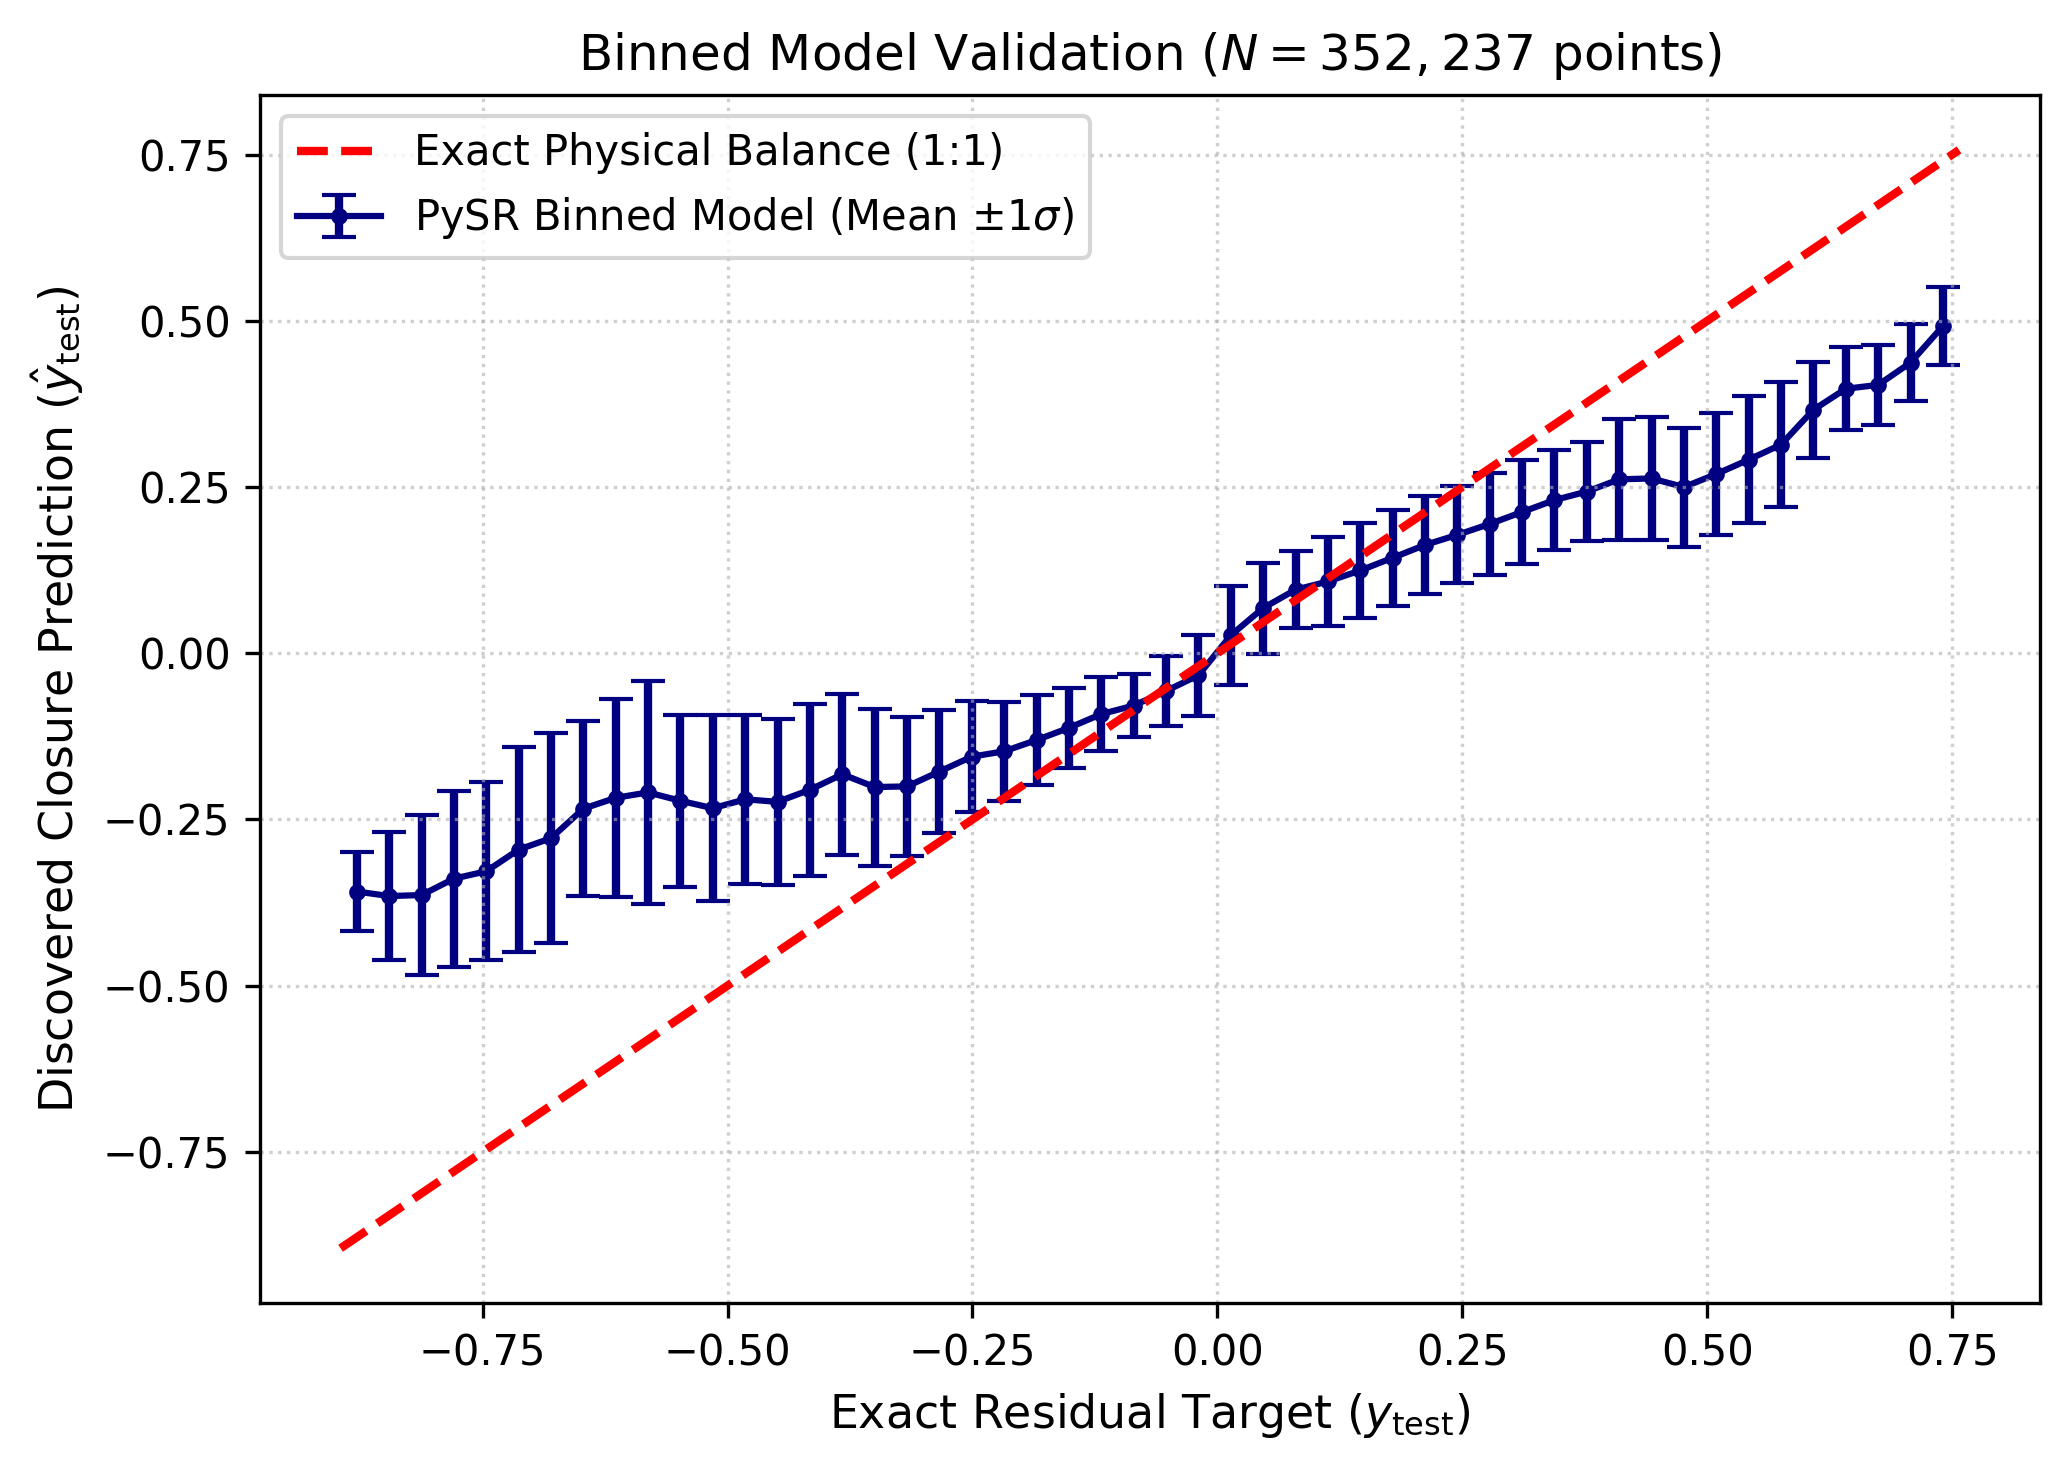

In [45]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binned_statistic

y_pred_test = model.predict(X_test, index=18)

num_bins = 50
bin_means_pred, bin_edges, _ = binned_statistic(y_test, y_pred_test, statistic='mean', bins=num_bins)
bin_stds_pred, _, _ = binned_statistic(y_test, y_pred_test, statistic='std', bins=num_bins)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])


plt.figure(figsize=(7, 5), dpi=300)

min_val, max_val = np.min(y_test), np.max(y_test)
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2.0, zorder=5, label='Exact Physical Balance (1:1)')

plt.errorbar(
    bin_centers, bin_means_pred, yerr=bin_stds_pred, 
    fmt='o-', color='navy', ecolor='navy', elinewidth=2.0, capsize=4, ms=3,
    zorder=1, label=r'PySR Binned Model (Mean $\pm 1\sigma$)'
)

plt.xlabel('Exact Residual Target ($y_{\mathrm{test}}$)', fontsize=11)
plt.ylabel('Discovered Closure Prediction ($\hat{y}_{\mathrm{test}}$)', fontsize=11)
plt.title(f'Binned Model Validation ($N = {len(y_test):,}$ points)', fontsize=12)
plt.legend(frameon=True, loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
# plt.savefig('binned_residual_validation.pdf', dpi=300)
plt.show()

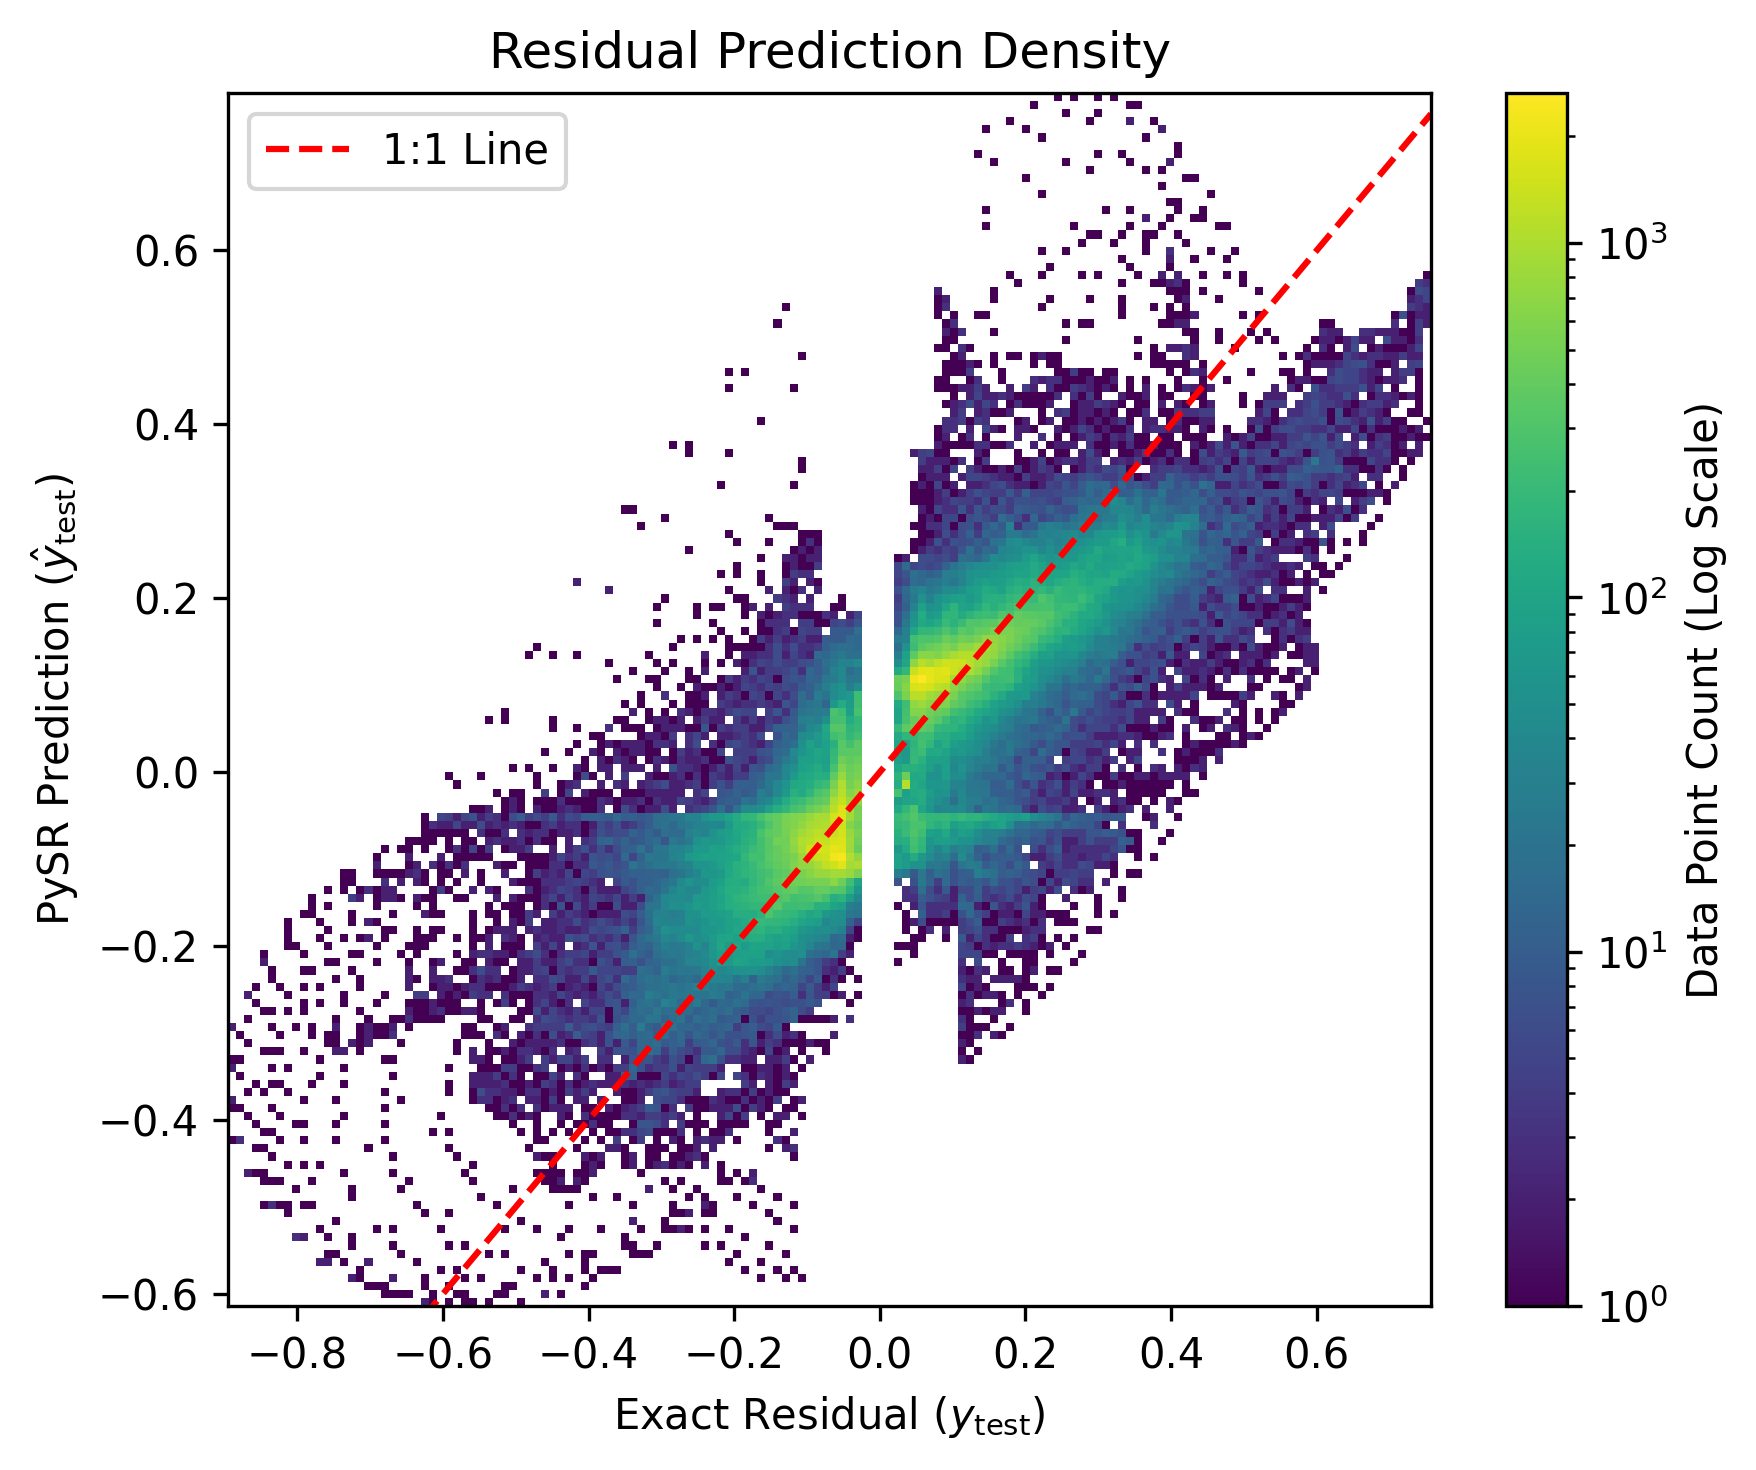

In [46]:
plt.figure(figsize=(6, 5), dpi=300)
plt.hist2d(y_test, y_pred_test, bins=150, cmap='viridis', norm=plt.cm.colors.LogNorm())
plt.colorbar(label='Data Point Count (Log Scale)')
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=1.5, label='1:1 Line')

plt.xlabel('Exact Residual ($y_{\mathrm{test}}$)')
plt.ylabel('PySR Prediction ($\hat{y}_{\mathrm{test}}$)')
plt.title('Residual Prediction Density')
plt.legend(loc='upper left')
plt.tight_layout()
# plt.savefig('density_residual_validation.pdf', dpi=300)
plt.show()

In [47]:
import numpy as np

y_pred_test = model.predict(X_test, index=18)
residuals = y_pred_test - y_test
abs_errors = np.abs(residuals)

# 3. Core Regression Metrics
ss_res = np.sum(residuals ** 2)
ss_tot = np.sum((y_test - np.mean(y_test)) ** 2)
r2 = 1 - (ss_res / ss_tot)

rmse = np.sqrt(np.mean(residuals ** 2))
mae = np.mean(abs_errors)
max_abs_err = np.max(abs_errors)

# 4. Standardized Metrics (relative to signal standard deviation)
std_y = np.std(y_test)
nrmse = rmse / std_y  # Normalized RMSE

# Print Publication Summary Table
print("=" * 50)
print("       STATISTICAL MODEL PERFORMANCE METRICS       ")
print("=" * 50)
print(f"• R-squared (R² Score)      : {r2:.6f}")
print(f"• Root Mean Squared Error  : {rmse:.6f}")
print(f"• Mean Absolute Error (MAE) : {mae:.6f}")
print(f"• Max Absolute Error       : {max_abs_err:.6f}")
print(f"• Normalized RMSE (RMSE/σ)  : {nrmse:.6f}")
print(f"• Target Standard Dev (σ)   : {std_y:.6f}")
print("=" * 50)

       STATISTICAL MODEL PERFORMANCE METRICS       
• R-squared (R² Score)      : 0.718927
• Root Mean Squared Error  : 0.081040
• Mean Absolute Error (MAE) : 0.056223
• Max Absolute Error       : 0.671259
• Normalized RMSE (RMSE/σ)  : 0.530164
• Target Standard Dev (σ)   : 0.152859


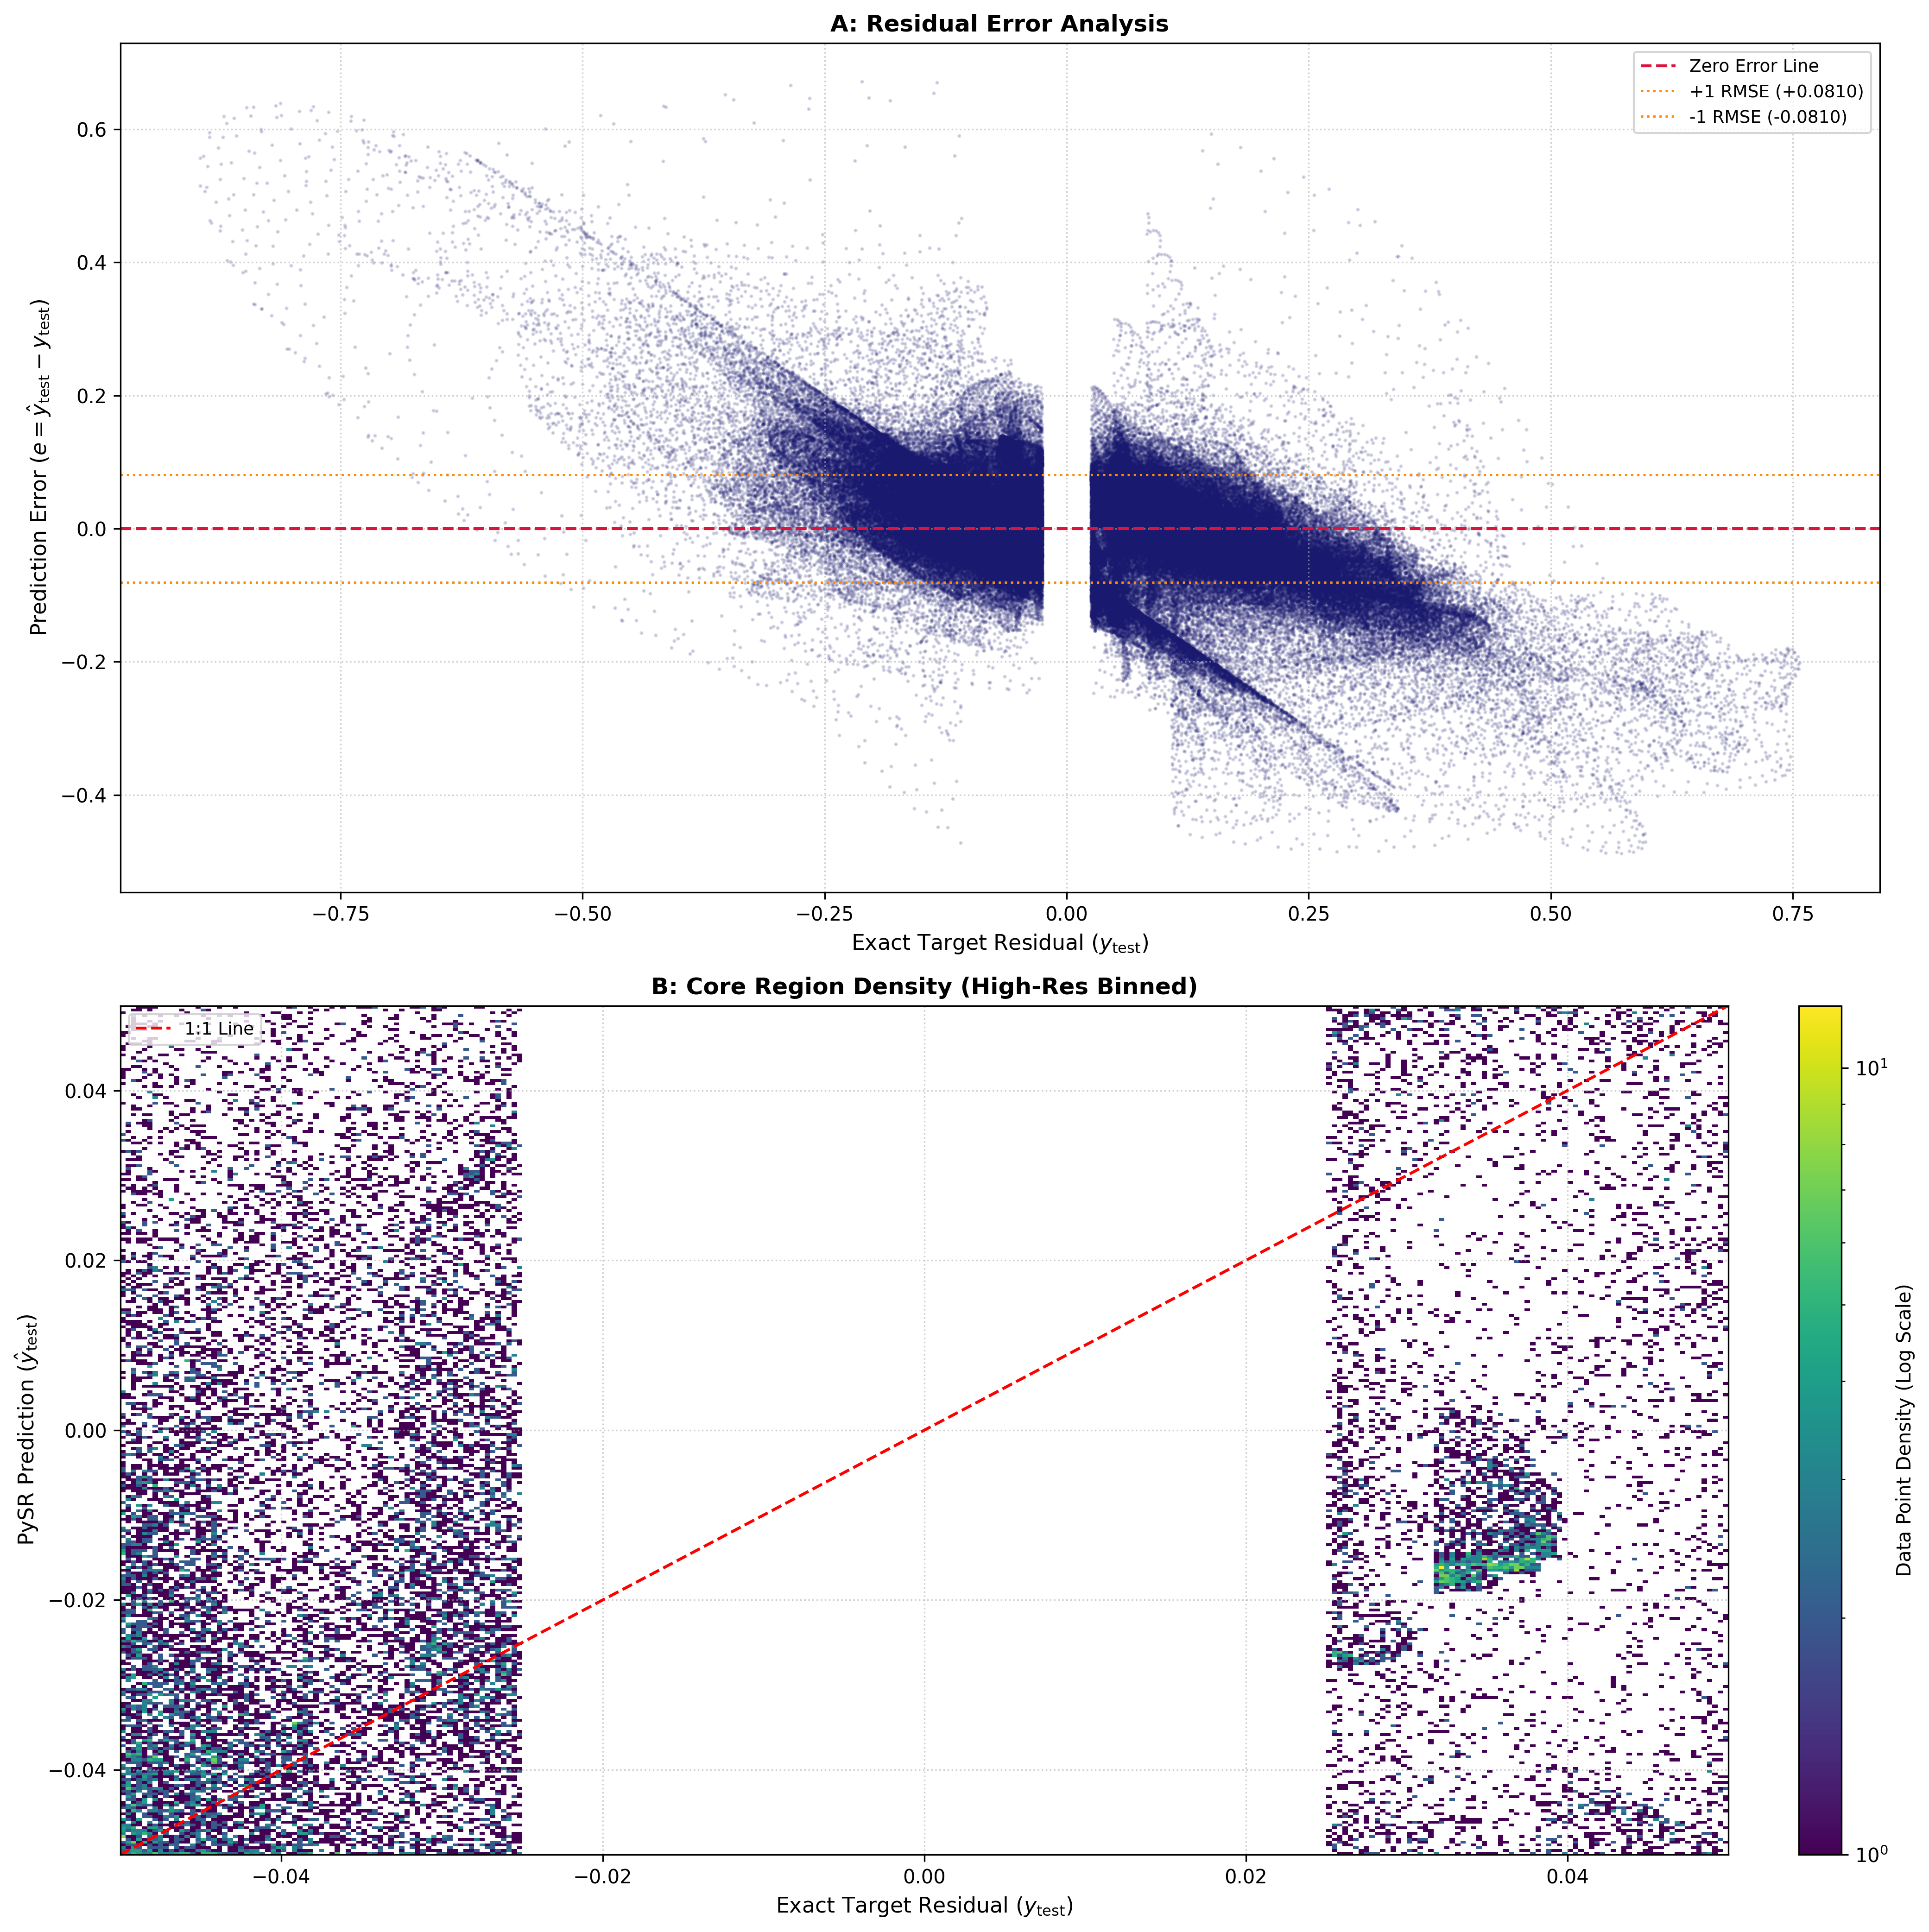

In [48]:
import matplotlib.pyplot as plt


# fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=300)
fig, axes = plt.subplots(2, 1, figsize=(14, 14), dpi=300)

# PANEL A: Residual Error Plot (e = y_pred - y_true vs y_true)
axes[0].scatter(y_test, residuals, alpha=0.15, s=1, color='midnightblue')
axes[0].axhline(0, color='crimson', linestyle='--', linewidth=1.5, label='Zero Error Line')

# 1-sigma boundary lines for context
axes[0].axhline(rmse, color='darkorange', linestyle=':', linewidth=1.2, label=f'+1 RMSE (+{rmse:.4f})')
axes[0].axhline(-rmse, color='darkorange', linestyle=':', linewidth=1.2, label=f'-1 RMSE (-{rmse:.4f})')

axes[0].set_xlabel('Exact Target Residual ($y_{\mathrm{test}}$)', fontsize=11)
axes[0].set_ylabel('Prediction Error ($e = \hat{y}_{\mathrm{test}} - y_{\mathrm{test}}$)', fontsize=11)
axes[0].set_title('A: Residual Error Analysis', fontsize=12, fontweight='bold')
# axes[0].set_ylim(-0.05, 0.05)  # Focus on the relevant error bound
axes[0].legend(loc='upper right', frameon=True, fontsize=9)
axes[0].grid(True, linestyle=':', alpha=0.6)


# PANEL B: High-Resolution Density Plot (Zoomed Core)
min_val_zoom, max_val_zoom = -0.05, 0.05

# Subset mask for core density focus
counts, xedges, yedges, im = axes[1].hist2d(
    y_test, y_pred_test, 
    bins=300, 
    range=[[min_val_zoom, max_val_zoom], [min_val_zoom, max_val_zoom]],
    cmap='viridis', 
    norm=plt.cm.colors.LogNorm()
)

axes[1].plot([min_val_zoom, max_val_zoom], [min_val_zoom, max_val_zoom], 'r--', lw=1.5, label='1:1 Line')
axes[1].set_xlabel('Exact Target Residual ($y_{\mathrm{test}}$)', fontsize=11)
axes[1].set_ylabel('PySR Prediction ($\hat{y}_{\mathrm{test}}$)', fontsize=11)
axes[1].set_title('B: Core Region Density (High-Res Binned)', fontsize=12, fontweight='bold')
axes[1].legend(loc='upper left', frameon=True, fontsize=9)
axes[1].grid(True, linestyle=':', alpha=0.6)

# shared colorbar
cbar = fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
cbar.set_label('Data Point Density (Log Scale)', fontsize=10)

plt.tight_layout()
# plt.savefig('residual_and_density_diagnostics.pdf', dpi=300)
plt.show()

In [7]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split

# Same train/test split you're already using for PySR
for label, cols in [("without curvature", [0, 1, 2, 3, 5, 8, 9, 10, 11, 12]),
                     ("with curvature", [0, 1, 2, 3, 5, 7, 8, 9, 10, 11, 12])]:
    gbr = GradientBoostingRegressor(n_estimators=300, max_depth=4, random_state=42)
    gbr.fit(X_tilde[train_idx][:, cols], y_res_tilde[train_idx])
    pred = gbr.predict(X_tilde[test_idx][:, cols])
    r2 = 1 - np.sum((y_res_tilde[test_idx]-pred)**2) / np.sum((y_res_tilde[test_idx]-y_res_tilde[test_idx].mean())**2)
    print(label, "R^2:", r2)

without curvature R^2: 0.8955957093018712
with curvature R^2: 0.891704990533089


Feature importances (descending):
  uy_tilde             0.4307
  dudx_tilde           0.1471
  ux_tilde             0.1067
  eta_tilde            0.0730
  hilbert_x_abs_tilde  0.0621
  hilbert_x_img_tilde  0.0472
  hilbert_t_img_tilde  0.0458
  duydx_tilde          0.0376
  hilbert_t_abs_tilde  0.0352
  deta_dx              0.0146


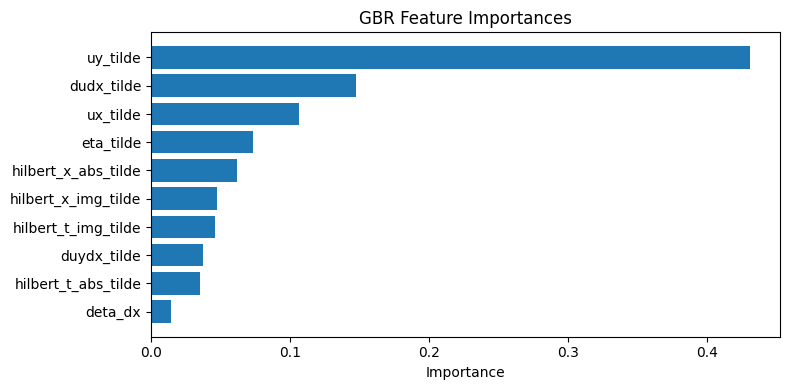

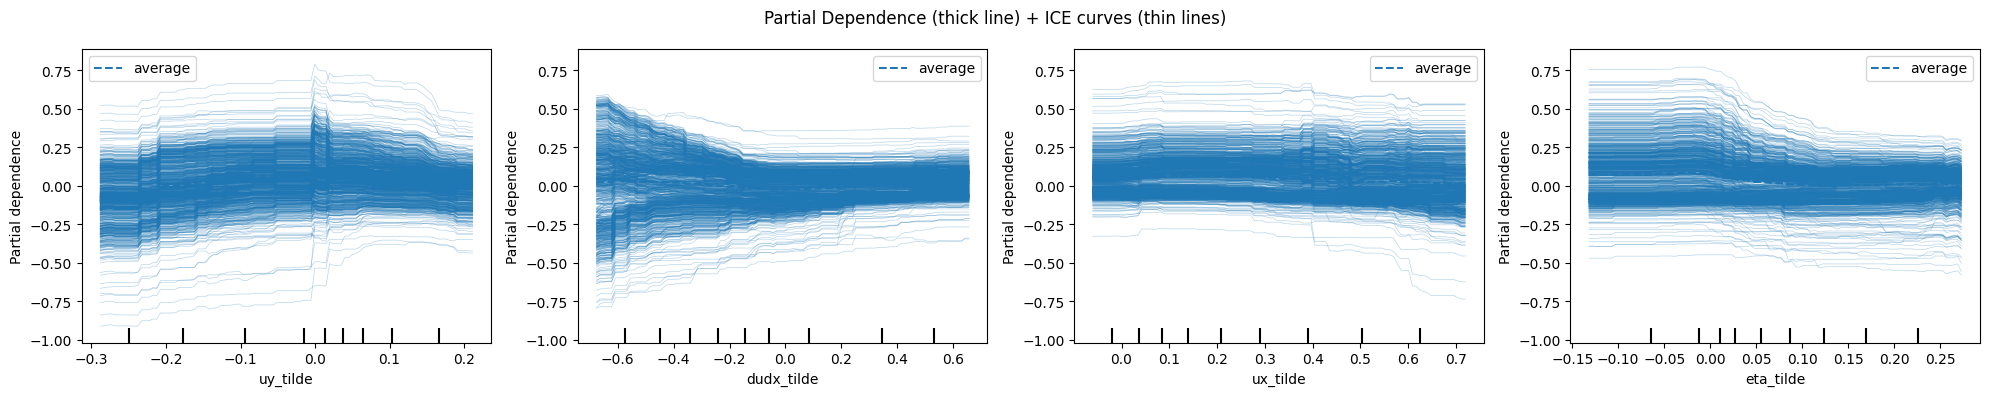

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.inspection import PartialDependenceDisplay
from sklearn.ensemble import GradientBoostingRegressor

# Refit GBR 
gbr = GradientBoostingRegressor(n_estimators=300, max_depth=4, random_state=42)
gbr.fit(X_tilde[train_idx][:, [0, 1, 2, 3, 5, 8, 9, 10, 11, 12]], y_res_tilde[train_idx])

feature_names_no_curv = [feature_names[i] for i in range(len(feature_names))
                          if keep_cols[i] in [0, 1, 2, 3, 5, 8, 9, 10, 11, 12]]  # adjust to match your actual list

# Feature importances
importances = gbr.feature_importances_
order = np.argsort(importances)[::-1]

print("Feature importances (descending):")
for i in order:
    print(f"  {feature_names_no_curv[i]:<20} {importances[i]:.4f}")

plt.figure(figsize=(8, 4))
plt.barh([feature_names_no_curv[i] for i in order], importances[order])
plt.xlabel("Importance")
plt.title("GBR Feature Importances")
plt.gca().invert_yaxis()
plt.tight_layout()
# plt.savefig("gbr_feature_importances.png", dpi=150)
plt.show()


top_k = 4
top_features = order[:top_k]

fig, ax = plt.subplots(1, top_k, figsize=(5 * top_k, 4))
PartialDependenceDisplay.from_estimator(
    gbr,
    X_tilde[train_idx][:, [0, 1, 2, 3, 5, 8, 9, 10, 11, 12]],
    features=list(top_features),
    feature_names=feature_names_no_curv,
    kind="both",   # "both" overlays individual ICE lines + the averaged PD curve
    ax=ax,
    n_jobs=-1,
)
plt.suptitle("Partial Dependence (thick line) + ICE curves (thin lines)")
plt.tight_layout()
# plt.savefig("gbr_partial_dependence.png", dpi=150)
plt.show()

In [7]:
import numpy as np
from pysr import PySRRegressor

uy_idx = feature_names.index("uy_tilde")
dudx_idx = feature_names.index("dudx_tilde")

uy_col = X_pysr[:, uy_idx]
dudx_col = X_pysr[:, dudx_idx]

sign_uy = np.sign(uy_col)
tanh_uy = np.tanh(50 * uy_col)
uy_dudx_interaction = uy_col * dudx_col

X_pysr_aug = np.column_stack([X_pysr, sign_uy, tanh_uy, uy_dudx_interaction])
feature_names_aug = feature_names + ["sign_uy", "tanh50_uy", "uy_times_dudx"]

print("Augmented feature set:", feature_names_aug)

X_train_aug = X_pysr_aug[train_idx]
y_train = y_res_tilde[train_idx]
X_test_aug = X_pysr_aug[test_idx]
y_test = y_res_tilde[test_idx]


def variable_appears(equation_str, varname):
    return varname in equation_str

seeds = [0, 1, 7, 42, 123]
results = []

# for seed in seeds:
#     print(f"\n=== Seed {seed} (original feature set) ===")
#     model = PySRRegressor(
#         niterations=60,
#         populations=30,
#         population_size=40,
#         binary_operators=["+", "-", "*", "/"],
#         unary_operators=["square", "cube", "abs", "sin", "cos", "tanh", "exp"],
#         parsimony=0.001,
#         maxsize=20,
#         # parallelism="multiprocessing",
#         # procs=8,
#         random_state=seed,
#         deterministic=False,
#     )
#     model.fit(X_pysr[train_idx], y_train, variable_names=feature_names)

#     hof = model.equations_
#     uy_hits = hof["equation"].apply(lambda eq: variable_appears(eq, "uy_tilde"))
#     print(f"  Equations using uy_tilde: {uy_hits.sum()} / {len(hof)}")
#     results.append({"seed": seed, "uy_tilde_hits": uy_hits.sum(), "n_eqs": len(hof),
#                      "best_loss": hof["loss"].min()})

# print("\nSummary across seeds:")
# for r in results:
#     print(r)


model_aug = PySRRegressor(
    niterations=100,
    populations=30,
    population_size=40,
    binary_operators=["+", "-", "*", "/"],
    unary_operators=["square", "cube", "abs", "sin", "cos", "tanh", "exp"],
    parsimony=0.001,
    maxsize=20,
    # parallelism="multiprocessing",
    # procs=8,
    random_state=42,
)

model_aug.fit(X_train_aug, y_train, variable_names=feature_names_aug)

hof_aug = model_aug.equations_
print("\n--- Full Pareto front (augmented feature set) ---")
print(hof_aug[["complexity", "loss", "equation"]].to_string(index=False))

for feat in ["uy_tilde", "sign_uy", "tanh50_uy", "uy_times_dudx"]:
    hits = hof_aug["equation"].apply(lambda eq: variable_appears(eq, feat)).sum()
    print(f"Equations using {feat}: {hits} / {len(hof_aug)}")

# Compare best-in-front performance vs. your earlier no-curvature run
y_pred_aug = model_aug.predict(X_test_aug)
r2_aug = 1 - np.sum((y_test - y_pred_aug)**2) / np.sum((y_test - y_test.mean())**2)
rmse_aug = np.sqrt(np.mean((y_test - y_pred_aug)**2))
print(f"\nAugmented-feature PySR: R^2 = {r2_aug:.4f}, RMSE = {rmse_aug:.4f}")
print("(compare against R^2 ~0.71 from the original feature set, and the GBR ceiling of ~0.90)")

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython
Augmented feature set: ['deta_dx', 'uy_tilde', 'ux_tilde', 'dudx_tilde', 'duydx_tilde', 'hilbert_t_img_tilde', 'hilbert_x_img_tilde', 'hilbert_t_abs_tilde', 'hilbert_x_abs_tilde', 'eta_tilde', 'sign_uy', 'tanh50_uy', 'uy_times_dudx']


c:\Users\Kshitij Jha\AppData\Local\Programs\Python\Python311\Lib\site-packages\pysr\sr.py:2811: UserWarning: Note: it looks like you are running in Jupyter. The progress bar will be turned off.
  warnings.warn(
Compiling Julia backend...
c:\Users\Kshitij Jha\AppData\Local\Programs\Python\Python311\Lib\site-packages\pysr\sr.py:1873: UserWarning: Note: Setting `random_state` without also setting `deterministic=True` and `parallelism='serial'` will result in non-deterministic searches.
  warnings.warn(
[ Info: Started!



Expressions evaluated per second: 6.080e+03
Progress: 24 / 3000 total iterations (0.800%)
════════════════════════════════════════════════════════════════════════════════════════════════════
───────────────────────────────────────────────────────────────────────────────────────────────────
Complexity  Loss       Score      Equation
1           2.398e-02  0.000e+00  y = 0.023353
3           1.447e-02  2.525e-01  y = tanh50_uy * 0.10752
4           1.447e-02  8.643e-06  y = tanh(tanh50_uy * 0.10791)
6           1.432e-02  5.176e-03  y = (tanh(tanh50_uy) * 0.13763) - -0.012382
───────────────────────────────────────────────────────────────────────────────────────────────────
════════════════════════════════════════════════════════════════════════════════════════════════════
Press 'q' and then <enter> to stop execution early.

Expressions evaluated per second: 1.170e+04
Progress: 92 / 3000 total iterations (3.067%)
══════════════════════════════════════════════════════════════════════════

[ Info: Final population:
[ Info: Results saved to:



--- Full Pareto front (augmented feature set) ---
 complexity     loss                                                                                                                                                               equation
          1 0.023979                                                                                                                                                            0.023353104
          2 0.023792                                                                                                                                              cube(hilbert_x_img_tilde)
          3 0.014471                                                                                                                                                 tanh50_uy * 0.10750971
          4 0.014471                                                                                                                                            sin(tanh50_uy) * 0.12675151
         